# Part I Support Vector Machine (SVM) Classification

## Task I.1 Engineering Problem and Dataset

We investigate whether motor-bearing vibration can distinguish normal operation from inner-race, ball, and outer-race faults. The Case Western Reserve University (CWRU) Bearing Data Center provides real measurements from a laboratory rig comprising a 2 hp electric motor, torque transducer/encoder, and dynamometer. Accelerometers mounted on the motor housing recorded vibration, while operating load and speed were documented. Localised bearing defects were deliberately introduced by electro-discharge machining; the recordings are experimental measurements, not synthetic signals [1, 2].

Our study combines normal baselines with drive-end fault experiments covering 0.007, 0.014, and 0.021 inch defect diameters and loads of 0-3 HP. Outer-race faults are restricted to the 6 o'clock position to limit positional variation. The selected fault group is documented at 12 kHz; baseline sampling rates and channel compatibility must be verified before combining recordings. Shared defect sizes retain SKF bearings and avoid introducing the manufacturer change associated with larger defects [2-4].

The SVM inputs are numerical descriptors derived from fixed-duration windows of drive-end acceleration, representing vibration energy, impulsiveness, and frequency content. Exact features, window duration, and any resampling will be justified during data preparation. The target is bearing condition: normal, inner-race fault, ball fault, or outer-race fault. Load, speed, defect diameter, position, and recording identity will initially be retained as metadata rather than predictors.

This classification could support condition monitoring by indicating whether inspection is warranted and which bearing component may be affected. Its value must be assessed with separated recordings and operating conditions; successful laboratory classification would not establish field reliability, natural degradation detection, or remaining useful life prediction.

Dataset citation: Case Western Reserve University, Bearing Data Center, Bearing Data Center [dataset], https://engineering.case.edu/bearingdatacenter. The provider supplies public downloads and describes condition-assessment research applications [5]. No explicit dataset license or blanket reuse permission was located in the reviewed sources; permission status remains unresolved, and unrestricted redistribution is not assumed.

Source references [1]-[5] and supporting notes are provided in [Readme.md â€” Sources for Task I.1](Readme.md#sources-for-task-i1).

## Task I.2 - Data Exploration and Preparation

We examine the original recording containers, their selected drive-end signals, and the engineered feature table. Each original recording is identified by its official numeric file ID. The four classes and experimental conditions follow Task I.1.

### Data acquisition and structure

The code resolves recording links from the original CWRU tables and preserves their original bytes in `public_dataset/`. Cached files are checked against acquisition checksums. It uses the variable whose ID matches the file, rather than taking the first available drive-end variable. Normal baseline DE signals are 48 kHz and the selected fault DE signals are 12 kHz, as documented in the benchmark's Tables A1-A2 [I.2-1, I.2-2]. Sampling rates are supplied by documentation, not inferred from recording length.


Output folders are created automatically. Each CSV-backed table image is regenerated when its producing code cell runs. Embedded markdown images are saved copies; after rerunning, save and close the notebook, run `python refresh_part_i_images.py`, then reopen it to refresh those copies. See Readme for the clean-rebuild sequence.


In [1]:
from pathlib import Path
from html.parser import HTMLParser
from urllib.parse import urljoin, urlparse
from urllib.request import urlopen, Request
from datetime import datetime, timezone
import hashlib
import json
import platform
import sys
import numpy as np
import pandas as pd
import scipy
from scipy.io import loadmat
from scipy.signal import resample_poly, butter, sosfiltfilt, periodogram
from scipy.stats import kurtosis
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from IPython.display import display, Image, Markdown

# Run with the notebook directory as the working directory.
ROOT = Path.cwd()
if not (ROOT / 'Part_I_SVM.ipynb').is_file():
    raise RuntimeError('Set the notebook kernel’s working directory to the folder containing both notebooks and the supporting project files (for instance, working directory "draft_A").\n\nTo set it, run the following in a notebook cell before running the project code, replacing the example path with your actual folder:\nimport os\nos.chdir(r"C:\\path\\to\\draft_A")\n\nConfirm the location with:\nfrom pathlib import Path\nprint(Path.cwd())\n\n"draft_A" is only an example folder name.')
RAW = ROOT / 'public_dataset'
DATA = ROOT / 'data'
FIGURES = ROOT / 'figures'
TABLE_FIGURES = ROOT / 'figures_of_data'
for folder in (RAW / 'source_pages', RAW / 'recordings', DATA, FIGURES, TABLE_FIGURES):
    folder.mkdir(parents=True, exist_ok=True)
BASE = 'https://engineering.case.edu/bearingdatacenter/'
CLASSES = ['normal', 'inner_race', 'ball', 'outer_race']
CLASS_LABELS = ['Normal', 'Inner race', 'Ball', 'Outer race']
COLORS = ['#31688e', '#d65f36', '#8a63a6', '#299576']
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})


FIGURE_HEADINGS = {
    'I2_class_distribution.png': ('Class distribution at two observation levels', 'I.2', 5),
    'I2_waveforms_spectra.png': ('Prepared signals: 0 HP; faults at 0.007 inch; shared amplitude and PSD scales', 'I.2', 5),
    'I2_feature_distributions.png': ('Window feature distributions; black dots are individual recording medians', 'I.2', 5),
    'I2_feature_correlations.png': ('Feature relationships across windows', 'I.2', 5),
    'I2_anomaly_diagnostics.png': ('Raw-signal anomaly diagnostics', 'I.2', 6),
    'I4_rbf_validation_heatmap.png': ('Validation macro-F1: RBF SVM (orange border: selected)', 'I.4', 10),
    'I4_regularisation_curves.png': ('Training and validation performance across regularisation strengths', 'I.4', 10),
    'I5_confusion_matrices.png': ('Test-set confusion matrices', 'I.5', 12),
}


def save_figure(fig, name, dpi=160):
    """Save a figure with a consistent two-line heading and space above its panels."""
    title, task, code_cell = FIGURE_HEADINGS[name]
    if name in ('I2_feature_correlations.png', 'I4_rbf_validation_heatmap.png'):
        fig.axes[0].set_title('')
    # Keep the panel area generous after adding the task and code-cell reference.
    fig.set_size_inches(fig.get_figwidth(), fig.get_figheight() + 0.65)
    fig.suptitle(f'{title}\nTask {task} | Notebook code cell {code_cell}',
                 fontfamily='DejaVu Sans', fontsize=12, fontweight='normal',
                 linespacing=1.6)
    fig.get_layout_engine().set(h_pad=0.16, w_pad=0.06)
    fig.savefig(FIGURES / name, dpi=dpi, bbox_inches='tight', facecolor='white')
    plt.close(fig)



# CSV-backed table images are rebuilt when their producing cells run.
import csv
from PIL import Image as TableImage, ImageDraw, ImageFont


def render_data_table(csv_name, title, code_cell):
    """Render all CSV rows and values; preserve the source CSV without changes."""
    with (DATA / csv_name).open(encoding='utf-8-sig', newline='') as stream:
        rows = list(csv.reader(stream))
    font = ImageFont.truetype('C:/Windows/Fonts/consola.ttf', 13)
    bold = ImageFont.truetype('C:/Windows/Fonts/consolab.ttf', 13)
    small = ImageFont.truetype('C:/Windows/Fonts/consola.ttf', 13)
    widths = [int(max((bold if i == 0 else font).getlength(row[j])
                      for i, row in enumerate(rows))) + 16 for j in range(len(rows[0]))]
    image = TableImage.new('RGB', (max(sum(widths) + 32, int(bold.getlength(title)) + 32),
                                  80 + 25 * len(rows)), 'white')
    draw = ImageDraw.Draw(image)
    draw.text((16, 12), title, fill='#172b45', font=bold)
    draw.text((16, 35), f'Nb code cell {code_cell}', fill='#486581', font=small)
    for i, row in enumerate(rows):
        left, top = 16, 65 + i * 25
        for width, value in zip(widths, row):
            draw.rectangle((left, top, left + width, top + 25),
                           fill='#e5edf6' if i == 0 else ('#f5f7fa' if i % 2 else 'white'), outline='#ccd4de')
            draw.text((left + 8, top + 5), value, fill='#172b45', font=bold if i == 0 else font)
            left += width
    image.save(TABLE_FIGURES / Path(csv_name).with_suffix('.png').name)
    image.close()


def download_bytes(url):
    """Read from the original HTTPS host, retaining normal TLS verification."""
    if urlparse(url).hostname != 'engineering.case.edu' or urlparse(url).scheme != 'https':
        raise ValueError(f'Unexpected source URL: {url}')
    with urlopen(Request(url, headers={'User-Agent': 'Assignment3Research/1.0'}), timeout=60) as response:
        if urlparse(response.url).hostname != 'engineering.case.edu':
            raise ValueError('Unexpected redirect outside the source host.')
        return response.read()


class SourceLinks(HTMLParser):
    """Collect anchor labels and URLs from an official recording table."""
    def __init__(self):
        """Initialise the current anchor and collected links."""
        super().__init__()
        self.links, self.href, self.parts = [], None, []

    def handle_starttag(self, tag, attrs):
        """Start collecting text when an anchor opens."""
        if tag == 'a':
            self.href, self.parts = dict(attrs).get('href'), []

    def handle_data(self, data):
        """Accumulate text within the current anchor."""
        if self.href is not None:
            self.parts.append(data)

    def handle_endtag(self, tag):
        """Store a completed anchor, including nested text."""
        if tag == 'a' and self.href is not None:
            self.links.append((''.join(''.join(self.parts).split()), self.href))
            self.href = None


def recording_specifications():
    """Describe the 40 recording labels selected from the official tables."""
    rows = []
    for load in range(4):
        rows.append(dict(slug='normal-baseline-data', label=f'Normal_{load}',
                         condition='normal', diameter_inches=np.nan, load_hp=load))
    for diameter in ('007', '014', '021'):
        for prefix, condition in [('IR', 'inner_race'), ('B', 'ball'), ('OR', 'outer_race')]:
            for load in range(4):
                label = f'{prefix}{diameter}' + ('@6' if prefix == 'OR' else '') + f'_{load}'
                rows.append(dict(slug='12k-drive-end-bearing-fault-data', label=label,
                                 condition=condition, diameter_inches=float(f'0.{diameter}'), load_hp=load))
    return rows


def acquire_recordings():
    """Cache source pages and original MAT files; verify previously recorded hashes."""
    slugs = ['welcome', 'project-history', 'apparatus-and-procedures',
             'download-data-file', 'normal-baseline-data',
             '12k-drive-end-bearing-fault-data', 'fault-specifications', 'bearing-information']
    tables = {}
    for slug in slugs:
        page = RAW / 'source_pages' / f'{slug}.html'
        if not page.exists():
            payload = download_bytes(BASE + slug)
            if b'<html' not in payload.lower():
                raise ValueError(f'Not an HTML source page: {slug}')
            page.write_bytes(payload)
        parser = SourceLinks()
        parser.feed(page.read_text(encoding='utf-8'))
        tables[slug] = parser.links
    manifest_path = RAW / 'acquisition_manifest.json'
    prior = {row['source_url']: row for row in json.loads(manifest_path.read_text())} if manifest_path.exists() else {}
    rows = []
    for spec in recording_specifications():
        matches = {urljoin(BASE + spec['slug'], link) for label, link in tables[spec['slug']]
                   if label == spec['label']}
        if len(matches) != 1:
            raise ValueError(f'Missing or ambiguous official link: {spec["label"]}')
        url = matches.pop()
        local_file = Path(urlparse(url).path).name
        destination = RAW / 'recordings' / local_file
        payload = destination.read_bytes() if destination.exists() else download_bytes(url)
        if not payload.startswith(b'MATLAB 5.0 MAT-file'):
            raise ValueError(f'Unexpected recording format: {url}')
        digest = hashlib.sha256(payload).hexdigest()
        if url in prior and digest != prior[url]['sha256']:
            raise ValueError(f'Checksum mismatch: {local_file}')
        if not destination.exists():
            destination.write_bytes(payload)
        rows.append({**spec, 'source_url': url, 'local_file': local_file,
                     'bytes': len(payload), 'sha256': digest,
                     'retrieved_utc': prior.get(url, {}).get('retrieved_utc', datetime.now(timezone.utc).isoformat())})
    # Retain provenance beside the unchanged source recordings.
    serializable = [{k: (None if isinstance(v, float) and np.isnan(v) else v)
                     for k, v in row.items()} for row in rows]
    manifest_path.write_text(json.dumps(serializable, indent=2) + '\n', encoding='utf-8')
    return rows


source_records = acquire_recordings()
print(f'{len(source_records)} original files; {sum(r["bytes"] for r in source_records):,} bytes.')
versions = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
            'scipy': scipy.__version__, 'matplotlib': matplotlib.__version__, 'scikit-learn': sklearn.__version__}
display(pd.Series(versions, name='Version').to_frame())

40 original files; 140,322,880 bytes.


,Version
python,3.14.7
numpy,2.5.3
pandas,3.0.6
scipy,1.18.1
matplotlib,3.11.2
scikit-learn,1.9.1


### Recording audit and anomalies

We audit all stored numeric variables and select one DE signal per recording. Hashes identify exact duplicate files and signals; long constant runs flag possible dropouts without treating ordinary quantisation as corruption. RPM is contextual metadata, so absent RPM values are retained as missing rather than fabricated. Normal fault diameter is not applicable, not an unknown measurement.

Negative acceleration is valid. We do not impose an unsupported amplitude limit or remove statistical extremes automatically. The benchmark reports possible peak truncation (clipping) in 236DE and 237DE [I.2-2]; these records remain included with quality flags. A flag indicates a measurement limitation, not a physically impossible bearing state.

In [2]:
def signal_hash(values):
    """Hash numeric signal content in a consistent float64 representation."""
    return hashlib.sha256(np.asarray(values, dtype='<f8').reshape(-1).tobytes()).hexdigest()


def longest_constant_run(values):
    """Return the largest number of consecutive exactly equal samples."""
    changes = np.flatnonzero(np.diff(values) != 0) + 1
    return int(np.diff(np.r_[0, changes, len(values)]).max())


def audit_recordings(records):
    """Inspect MAT variables, select ID-matched DE channels, and retain quality metadata."""
    inventory, channel_rows, signals = [], [], {}
    first_channel = {}
    for row in records:
        file_id = int(Path(row['local_file']).stem)
        prefix = f'X{file_id:03d}'
        contents = loadmat(RAW / 'recordings' / row['local_file'])
        selected = prefix + '_DE_time'
        if selected not in contents:
            raise ValueError(f'Missing expected DE channel: {selected}')
        for key, values in contents.items():
            if key.startswith('__'):
                continue
            numeric = np.issubdtype(values.dtype, np.number)
            digest = signal_hash(values) if numeric and key.endswith('_time') else ''
            duplicate_of = first_channel.get(digest, '') if digest else ''
            channel_rows.append(dict(recording_id=file_id, variable=key,
                                     shape=str(values.shape), dtype=str(values.dtype),
                                     missing_values=int(np.isnan(values).sum()) if numeric else np.nan,
                                     infinite_values=int(np.isinf(values).sum()) if numeric else np.nan,
                                     selected_de=key == selected, duplicate_of=duplicate_of))
            if digest and not duplicate_of:
                first_channel[digest] = f'{file_id}:{key}'
        original = contents[selected]
        if original.ndim != 2 or 1 not in original.shape or not np.isrealobj(original):
            raise ValueError(f'Expected a real signal vector: {selected}')
        x = np.asarray(original, dtype=np.float64).reshape(-1)
        if len(x) == 0 or not np.isfinite(x).all():
            raise ValueError(f'Empty or non-finite DE data: {file_id}; investigate before processing.')
        sample_rate = 48000 if row['condition'] == 'normal' else 12000
        rpm_key = prefix + 'RPM'
        rpm = float(contents[rpm_key].item()) if rpm_key in contents else np.nan
        if np.isfinite(rpm) and rpm <= 0:
            raise ValueError(f'Non-positive RPM for a running motor: {file_id}')
        extra = [k for k in contents if k.endswith('_time') and not k.startswith(prefix + '_')]
        inventory.append({**row, 'recording_id': file_id, 'selected_variable': selected,
                          'original_shape': str(original.shape), 'dtype': str(original.dtype),
                          'sample_rate_hz': sample_rate, 'samples': len(x), 'duration_s': len(x) / sample_rate,
                          'rpm': rpm, 'rpm_missing': not np.isfinite(rpm), 'extra_signals': ';'.join(extra),
                          'nan_count': int(np.isnan(x).sum()), 'inf_count': int(np.isinf(x).sum()),
                          'minimum': x.min(), 'maximum': x.max(), 'mean': x.mean(), 'std': x.std(),
                          'longest_constant_run': longest_constant_run(x),
                          'possible_clipping_reported': file_id in (236, 237),
                          'signal_sha256': signal_hash(x)})
        signals[file_id] = x
    return pd.DataFrame(inventory), pd.DataFrame(channel_rows), signals


inventory, channels, raw_signals = audit_recordings(source_records)
assert len(inventory) == 40 and inventory['recording_id'].is_unique
assert inventory['signal_sha256'].is_unique and inventory['sha256'].is_unique
assert (inventory['std'] > 0).all()
inventory.to_csv(DATA / 'I2_recording_inventory.csv', index=False)
render_data_table('I2_recording_inventory.csv', 'Task I.2 - Recording inventory', 2)
channels.to_csv(DATA / 'I2_channel_inventory.csv', index=False)
render_data_table('I2_channel_inventory.csv', 'Task I.2 - Channel inventory', 2)
display(channels.loc[channels['duplicate_of'].ne(''), ['recording_id', 'variable', 'duplicate_of']])
print('Selected DE NaNs:', inventory['nan_count'].sum(), '| infinities:', inventory['inf_count'].sum())
print('Exact duplicate selected DE signals:', inventory['signal_sha256'].duplicated().sum())
print('Longest exactly constant run:', inventory['longest_constant_run'].max(), 'samples')

,recording_id,variable,duplicate_of
6,99,X098_DE_time,98:X098_DE_time
7,99,X098_FE_time,98:X098_FE_time


Selected DE NaNs: 0 | infinities: 0
Exact duplicate selected DE signals: 0
Longest exactly constant run: 3 samples


**Recording inventory.** The inventory links each recording to its source and selected DE variable. Missing RPM is confined to metadata; peak truncation (clipping) flags identify measurement limitations rather than excluded records. The repeated recording ID aligns the three column blocks.

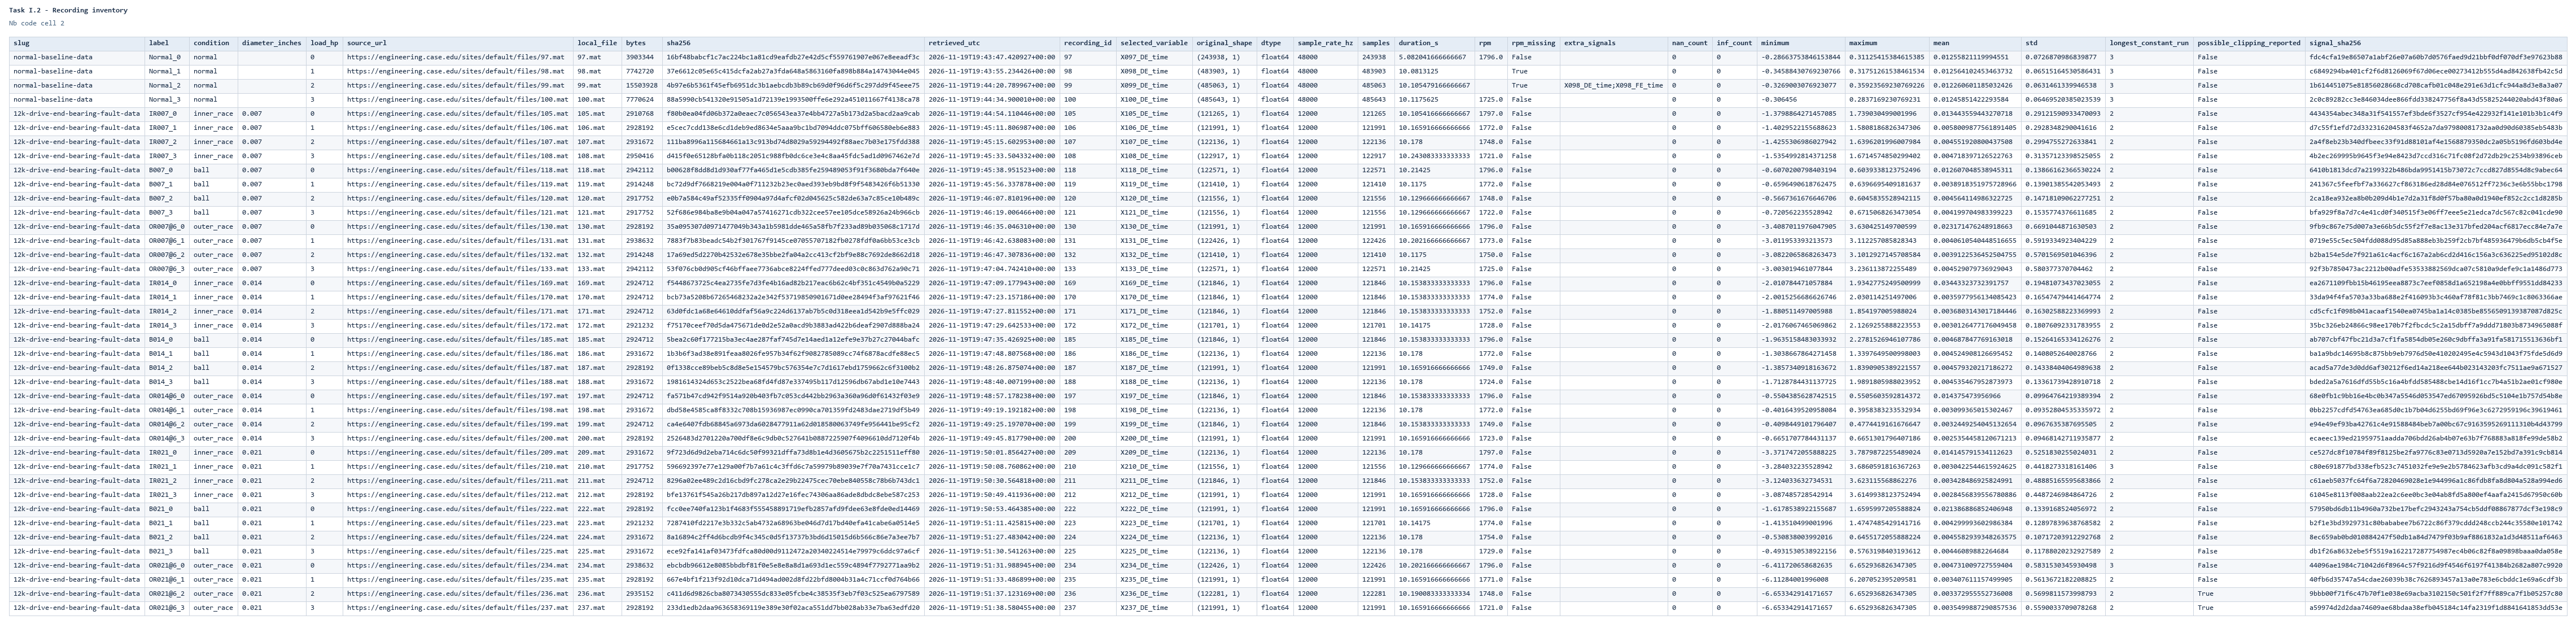

### Signal preparation and feature definitions

Normal DE signals are downsampled from 48 to 12 kHz using polyphase FIR anti-alias filtering [I.2-3]. All recordings then receive the same fourth-order Butterworth low-pass filter at 4.5 kHz, applied forward and backward [I.2-4]. This limits analysis away from the 6 kHz Nyquist boundary and reduces sensitivity to different high-frequency bandwidths; it does not make the original acquisition systems identical. A 0.05 s margin is removed from each end to reduce filter-edge effects.

We use consecutive, non-overlapping **0.25 s windows (3,000 samples)**. Each contains approximately seven shaft revolutions over the documented speeds and provides 4 Hz spectral-bin spacing. This is a fixed engineering choice, not an accuracy-tuned parameter. Incomplete final windows are discarded and counted. Each window is mean-centred, retaining AC vibration amplitude rather than normalising its energy.

| Feature | Definition and purpose |
|---|---|
| RMS | Square root of mean squared centred acceleration; overall vibration level |
| Peak-to-peak | Maximum minus minimum; amplitude range |
| Pearson kurtosis | Bias-corrected normalised fourth moment; impulsiveness, with Gaussian reference 3 [I.2-5] |
| Crest factor | Maximum absolute centred amplitude divided by RMS; relative peak magnitude |
| Spectral centroid | Power-weighted mean frequency; frequency-content location |
| Spectral entropy | Entropy of normalised spectral power divided by log(number of bins); spectral spread |
| Low-band fraction | Fraction of spectral power below 1 kHz |
| Mid-band fraction | Fraction from 1 kHz to below 3 kHz |

Spectral features use a Hann-window periodogram with no zero padding. Bands are broad descriptors, not claims about specific fault frequencies. The high-band fraction is omitted because the three fractions sum to one. Standard deviation is omitted because it equals RMS after centring. Load, RPM, fault size, recording ID and quality flags are metadata, not model inputs.

Signal preparation is imported from `signal_preparation.py`, stored alongside both notebooks. Parts I and II use the same function for resampling, filtering and edge trimming. All 1,578 reconstructed windows match Part I's saved hashes, confirming unchanged preparation results.

In [3]:
from signal_preparation import (FS, WINDOW_SECONDS, WINDOW_SAMPLES, EDGE_SAMPLES,
                                LOWPASS, prepare_signal)

FEATURES = ['rms', 'peak_to_peak', 'kurtosis', 'crest_factor', 'spectral_centroid_hz',
            'spectral_entropy', 'low_band_fraction', 'mid_band_fraction']




def window_features(values):
    """Return eight amplitude, impulsiveness and spectral descriptors for one window."""
    x = values - np.mean(values)
    rms = np.sqrt(np.mean(x ** 2))
    if not np.isfinite(x).all() or rms <= 0:
        raise ValueError('Non-finite or zero-energy window; investigate rather than impute.')
    frequencies, power = periodogram(x, fs=FS, window='hann', detrend=False, scaling='density')
    weights = power / power.sum()
    positive = weights > 0
    return dict(rms=rms, peak_to_peak=np.ptp(x),
                kurtosis=kurtosis(x, fisher=False, bias=False, nan_policy='raise'),
                crest_factor=np.max(np.abs(x)) / rms,
                spectral_centroid_hz=np.sum(frequencies * weights),
                spectral_entropy=-np.sum(weights[positive] * np.log(weights[positive])) / np.log(len(weights)),
                low_band_fraction=weights[frequencies < 1000].sum(),
                mid_band_fraction=weights[(frequencies >= 1000) & (frequencies < 3000)].sum())


def create_feature_table(recordings, signals):
    """Extract disjoint windows while retaining recording identity and quality flags."""
    rows, processing, prepared = [], [], {}
    for rec in recordings.to_dict('records'):
        file_id = rec['recording_id']
        x = prepare_signal(signals[file_id], rec['sample_rate_hz'])
        prepared[file_id] = x
        count, tail = divmod(len(x), WINDOW_SAMPLES)
        processing.append(dict(recording_id=file_id, condition=rec['condition'],
                               prepared_samples=len(x), windows=count, discarded_tail_samples=tail,
                               edge_trimmed_samples=2 * EDGE_SAMPLES, effective_fs_hz=FS))
        for number in range(count):
            start = number * WINDOW_SAMPLES
            segment = x[start:start + WINDOW_SAMPLES]
            raw_start = int(round((start + EDGE_SAMPLES) * rec['sample_rate_hz'] / FS))
            raw_stop = int(round((start + WINDOW_SAMPLES + EDGE_SAMPLES) * rec['sample_rate_hz'] / FS))
            original = signals[file_id][raw_start:raw_stop]
            rows.append(dict(recording_id=file_id, condition=rec['condition'],
                             diameter_inches=rec['diameter_inches'], load_hp=rec['load_hp'], rpm=rec['rpm'],
                             window_index=number, start_s=(start + EDGE_SAMPLES) / FS,
                             specimen_group='normal' if rec['condition'] == 'normal' else
                                 f'{rec["condition"]}_{rec["diameter_inches"]:.3f}',
                             possible_clipping_reported=rec['possible_clipping_reported'],
                             raw_abs_ge_6_65=int(np.count_nonzero(np.abs(original) >= 6.65)),
                             window_sha256=signal_hash(segment), **window_features(segment)))
    return pd.DataFrame(rows), pd.DataFrame(processing), prepared


features, processing, prepared_signals = create_feature_table(inventory, raw_signals)
X = features[FEATURES].copy()
y = features['condition'].copy()
groups = features['recording_id'].copy()
assert np.isfinite(X.to_numpy()).all()
assert (X[['rms', 'peak_to_peak', 'kurtosis']] > 0).all().all()
assert (X['crest_factor'] >= 1).all()
assert X['spectral_centroid_hz'].between(0, FS / 2).all()
assert X['spectral_entropy'].between(-1e-12, 1 + 1e-12).all()
assert X[['low_band_fraction', 'mid_band_fraction']].ge(0).all().all()
assert (X['low_band_fraction'] + X['mid_band_fraction'] <= 1 + 1e-12).all()
assert not features.duplicated(['recording_id', 'window_index']).any()
assert not features['window_sha256'].duplicated().any()
features.to_csv(DATA / 'I2_window_features.csv', index=False)
render_data_table('I2_window_features.csv', 'Task I.2 - Window feature inventory', 3)
processing.to_csv(DATA / 'I2_processing_summary.csv', index=False)
render_data_table('I2_processing_summary.csv', 'Task I.2 - Signal processing summary', 3)

# Save the three dataset checks as a table instead of printing duplicate output.
dataset_summary = pd.DataFrame([
    {'measurement': 'Model input dimensions',
     'value': f'{X.shape[0]} observations x {X.shape[1]} float64 features'},
    {'measurement': 'Exact duplicate feature vectors',
     'value': str(int(X.duplicated().sum()))},
    {'measurement': 'Discarded final partial-window samples',
     'value': f'{processing["discarded_tail_samples"].sum():,} at 12 kHz'}
])
dataset_summary.to_csv(DATA / 'I2_dataset_summary.csv', index=False)
render_data_table('I2_dataset_summary.csv', 'Task I.2 - Dataset summary', 3)


The prepared dataset contains **1,578 observations and eight float64 features**, with no exact duplicate feature vectors. Windowing discards **33,787 samples across the recordings** because the final segments are shorter than a complete window. At 12 kHz, this totals approximately **2.82 seconds**. This total excludes the separate filter-edge trimming.

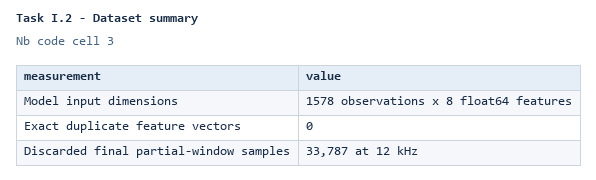

The table below previews the first five observations; values are rounded to four decimal places for display. Each row represents one non-overlapping 0.25 s vibration window, and the columns are the eight numerical SVM inputs. These examples come from the first recording, so they do not represent all four classes. The CSV retains the unrounded feature values.

In [4]:
display(X.head().round(4))

,rms,peak_to_peak,kurtosis,crest_factor,spectral_centroid_hz,spectral_entropy,low_band_fraction,mid_band_fraction
0,0.0632,0.4406,2.9084,3.5051,3025.3746,0.5465,0.2377,0.1168
1,0.0630,0.4107,2.7128,3.6634,2865.8721,0.5593,0.2811,0.1140
2,0.0625,0.4494,2.7168,4.1665,3006.6235,0.5441,0.2353,0.1278
3,0.0629,0.4430,2.9016,3.8415,2868.6751,0.5490,0.2768,0.1162
4,0.0615,0.4120,2.8173,3.4314,3015.8410,0.5514,0.2291,0.1250


**Processing summary.** This table accounts for retained samples, complete windows and discarded tails after preparation. Recording 97 produces fewer windows because its original duration is shorter; no padding or repeated windows compensate for that difference.

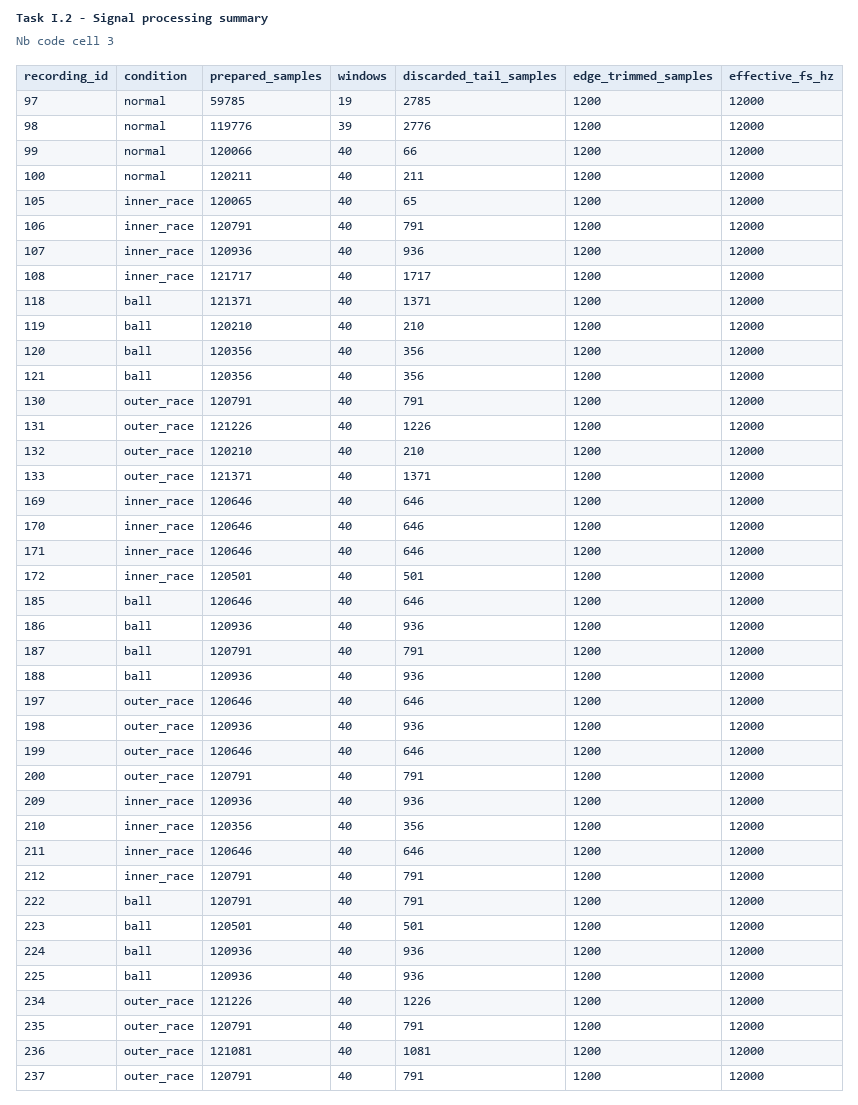

### Distributions, class relationships and imbalance

The figures describe this dataset; they are not classifier results. Representative traces use the same 0 HP load and 0.007 inch fault size, with matched plotting limits. Feature boxplots show all windows, with recording medians overlaid to expose between-recording variation. Adjacent windows are not independent bearing specimens. We retain recording and condition/size group identifiers for the evaluation design in Task I.3; the latter is a conservative grouping proxy, not a verified specimen identifier [I.2-6].

In [5]:
counts = pd.DataFrame({'recordings': inventory.groupby('condition').size(),
                       'windows': features.groupby('condition').size()}).reindex(CLASSES)
counts['window_percent'] = counts['windows'] / counts['windows'].sum() * 100
counts.to_csv(DATA / 'I2_class_distribution.csv', index_label='condition')
render_data_table('I2_class_distribution.csv', 'Task I.2 - Class distribution', 5)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout='constrained')
for ax, column in zip(axes, ['recordings', 'windows']):
    bars = ax.bar(CLASS_LABELS, counts[column], color=COLORS)
    ax.bar_label(bars, padding=3)
    ax.set(ylabel='Count', title=f'Number of {column}')
    ax.set_ylim(0, counts[column].max() * 1.18)
fig.suptitle('Class distribution at two observation levels')
save_figure(fig, 'I2_class_distribution.png')

representatives = [97, 105, 118, 130]
fig, axes = plt.subplots(4, 2, figsize=(11, 9), sharex='col', sharey='col', layout='constrained')
for i, (file_id, title) in enumerate(zip(representatives, CLASS_LABELS)):
    x = prepared_signals[file_id][:WINDOW_SAMPLES]
    x = x - x.mean()
    axes[i, 0].plot(np.arange(len(x)) / FS, x, color=COLORS[i], lw=0.7)
    axes[i, 0].set(title=f'{title} | recording {file_id}', ylabel='Acceleration (source units)')
    f, power = periodogram(x, fs=FS, window='hann', detrend=False)
    axes[i, 1].semilogy(f, np.maximum(power, 1e-14), color=COLORS[i], lw=0.8)
    axes[i, 1].set(title='Power spectral density', ylabel='Source units squared / Hz', xlim=(0, 6000))
axes[-1, 0].set_xlabel('Time within window (s)')
axes[-1, 1].set_xlabel('Frequency (Hz)')
fig.suptitle('Prepared signals: 0 HP; faults at 0.007 inch; shared amplitude and PSD scales')
save_figure(fig, 'I2_waveforms_spectra.png')

feature_titles = ['RMS', 'Peak-to-peak', 'Pearson kurtosis', 'Crest factor',
                  'Spectral centroid (Hz)', 'Spectral entropy', 'Power below 1 kHz', 'Power at 1-3 kHz']
record_medians = features.groupby(['condition', 'recording_id'])[FEATURES].median().reset_index()
fig, axes = plt.subplots(2, 4, figsize=(14, 7), layout='constrained')
for ax, feature, title in zip(axes.flat, FEATURES, feature_titles):
    series = [features.loc[y == label, feature] for label in CLASSES]
    box = ax.boxplot(series, tick_labels=CLASS_LABELS, patch_artist=True,
                     flierprops={'markersize': 2, 'alpha': .35})
    for patch, color in zip(box['boxes'], COLORS):
        patch.set(facecolor=color, alpha=.35)
    for i, label in enumerate(CLASSES, 1):
        medians = record_medians.loc[record_medians['condition'] == label, feature]
        ax.scatter(np.linspace(i - .12, i + .12, len(medians)), medians,
                   color='black', marker='.', s=15, zorder=3)
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=35)
fig.suptitle('Window feature distributions; black dots are individual recording medians')
save_figure(fig, 'I2_feature_distributions.png')

correlations = X.corr(method='spearman')
correlations.to_csv(DATA / 'I2_feature_correlations.csv', index_label='feature')
render_data_table('I2_feature_correlations.csv', 'Task I.2 - Feature correlations', 5)
fig, ax = plt.subplots(figsize=(9, 7), layout='constrained')
image = ax.imshow(correlations, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(len(FEATURES)), feature_titles, rotation=45, ha='right')
ax.set_yticks(range(len(FEATURES)), feature_titles)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        ax.text(j, i, f'{correlations.iloc[i,j]:.2f}', ha='center', va='center',
                fontsize=8, color='white' if abs(correlations.iloc[i,j]) > .65 else 'black')
fig.colorbar(image, ax=ax, shrink=.8, label='Spearman correlation')
ax.set_title('Feature relationships across windows')
save_figure(fig, 'I2_feature_correlations.png')

Fallback to a different backend


**Class distribution table.** Counts distinguish source recordings from the derived observations. The normal class remains the minority, so window totals alone should not be interpreted as equal evidence across bearing conditions.

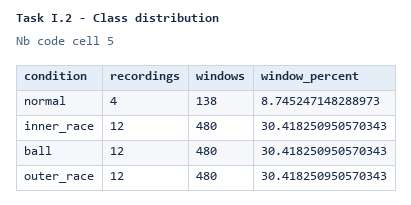

**Class distribution figure.** The panels show how the recording imbalance carries into the window dataset. The shorter normal recording further increases the difference at window level.

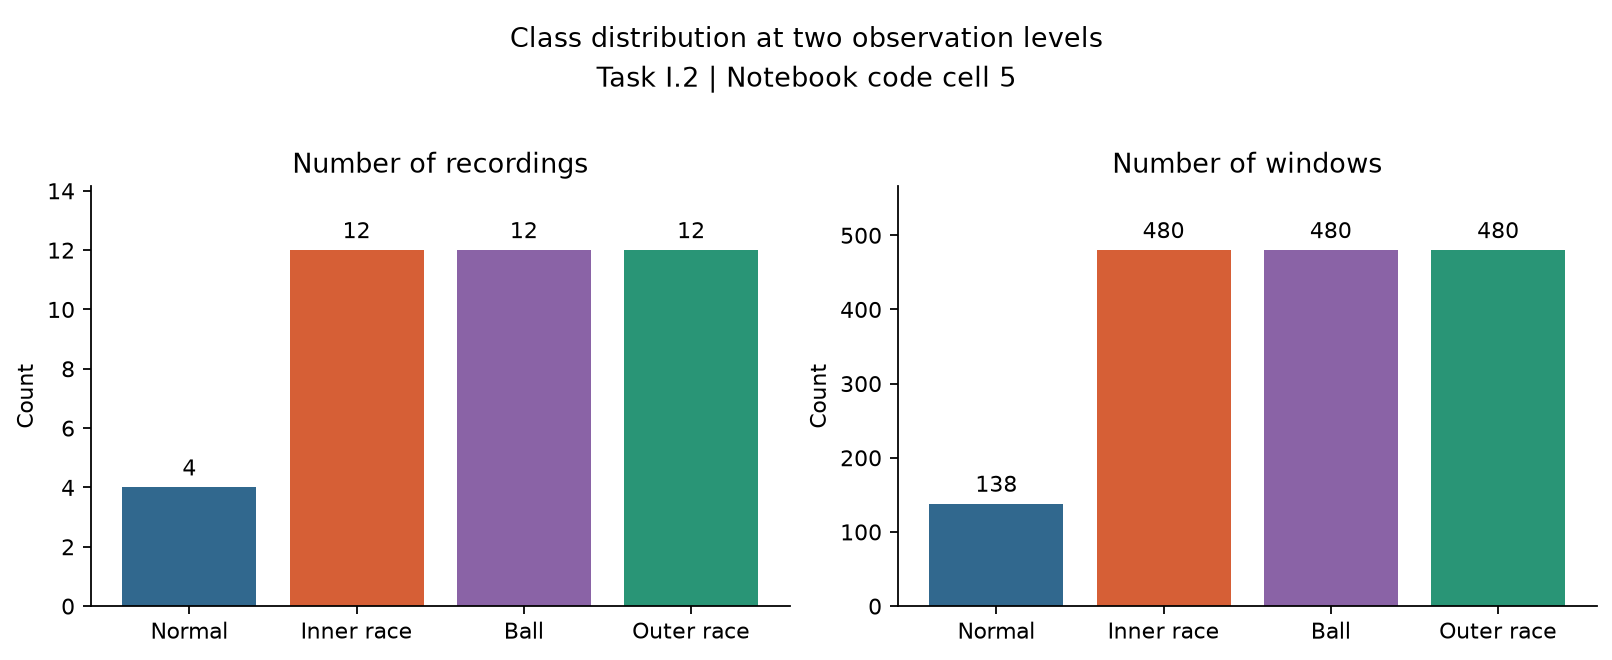

**Waveforms and spectra.** Shared amplitude and power-density scales make the selected conditions comparable. The inner-race and outer-race examples show stronger impulses, while spectral differences motivate frequency descriptors. These examples do not represent every fault size or operating load.

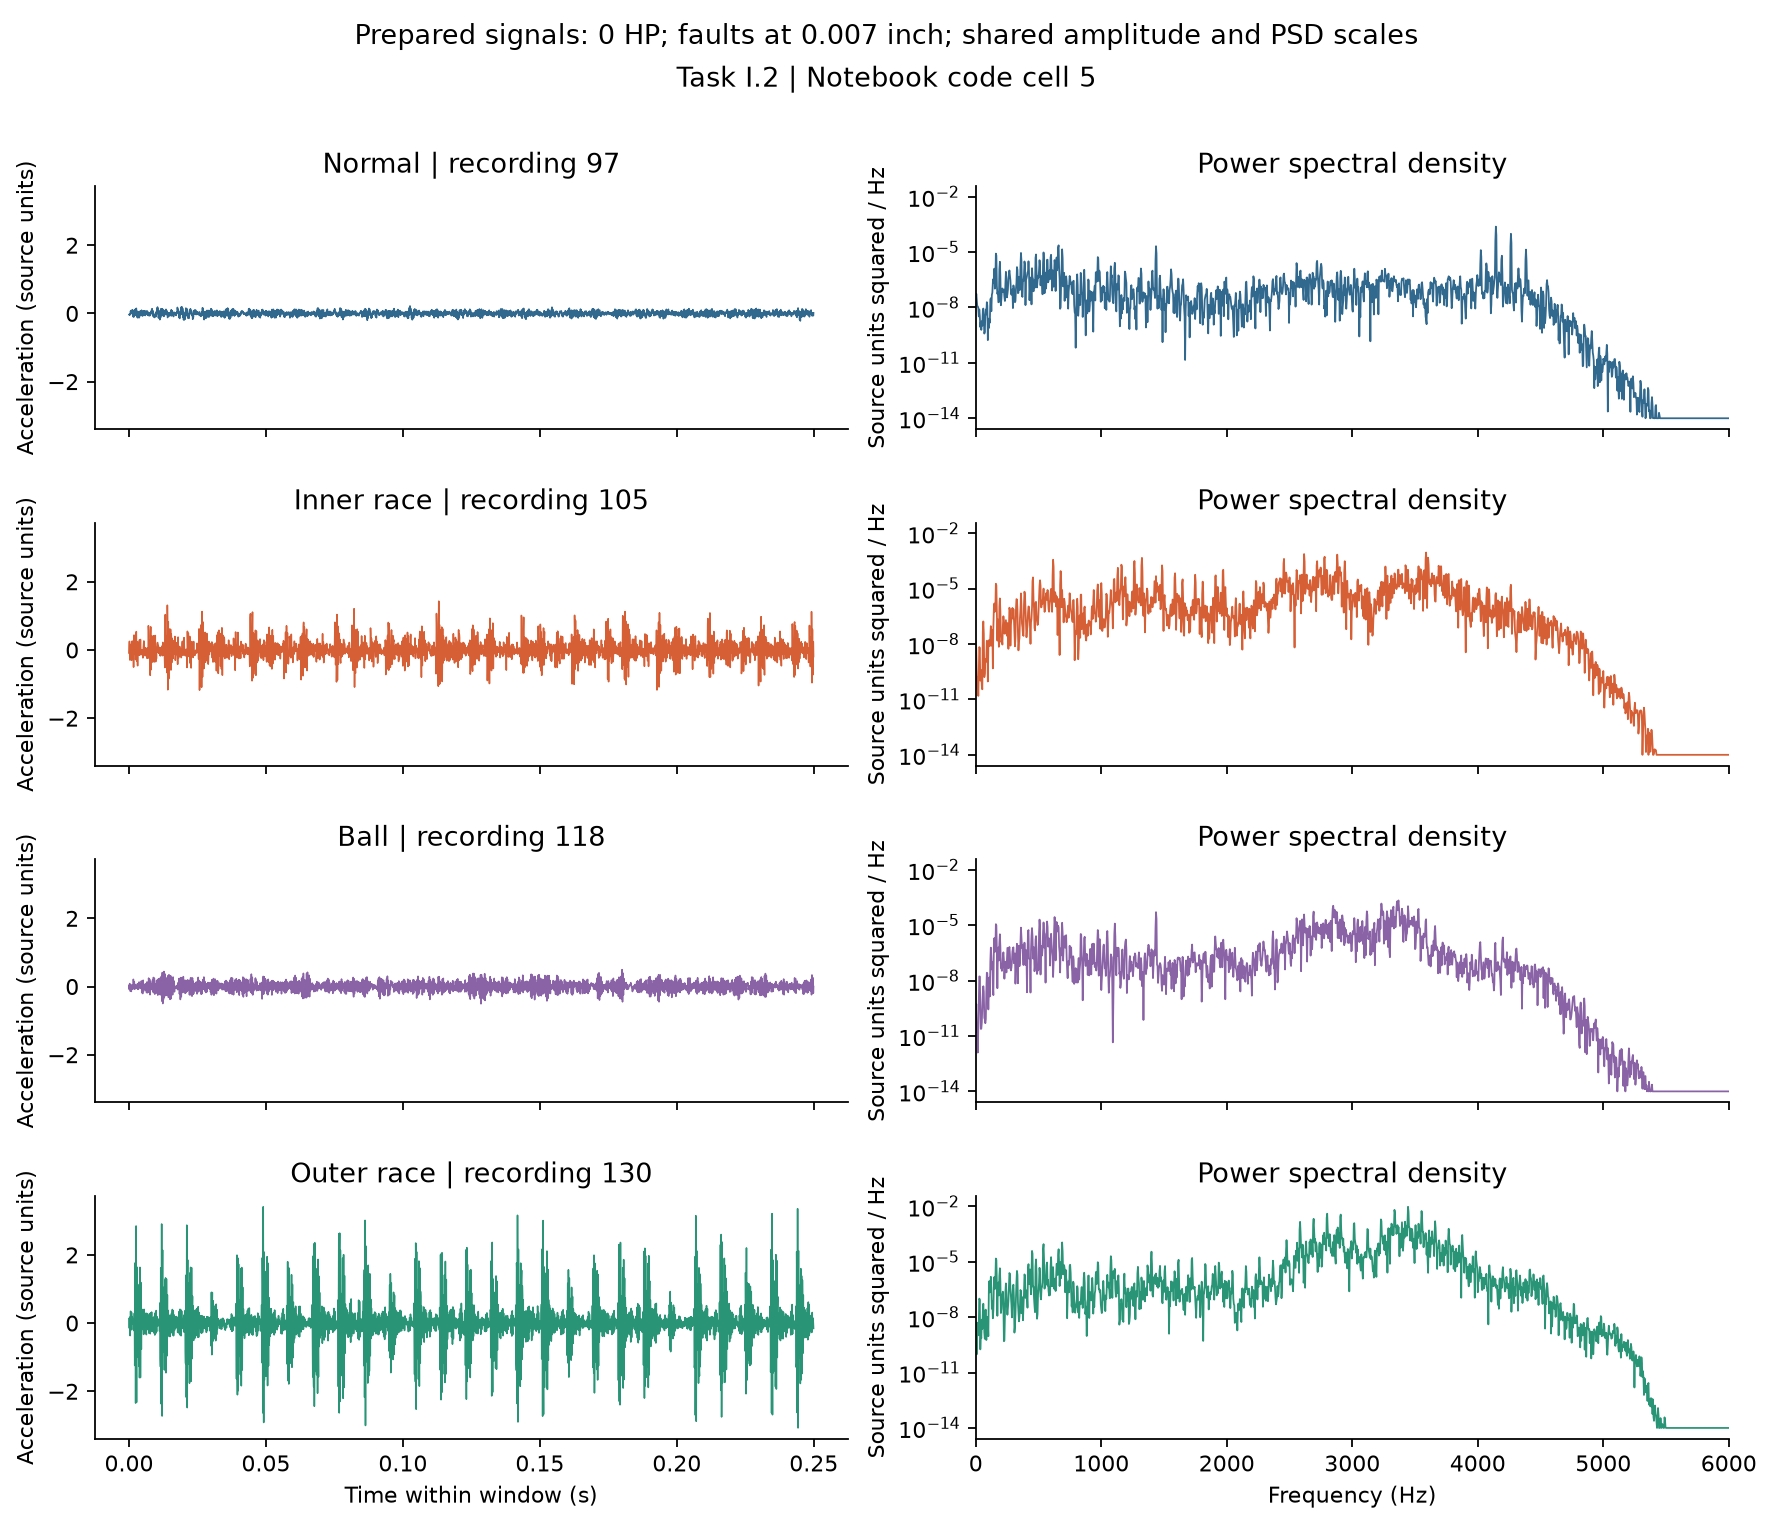

**Feature distributions.** Boxes summarise windows, while black dots show individual recording medians. The spread of those medians highlights between-recording variability; overlap among fault classes prevents interpreting a single feature as a complete diagnostic rule.

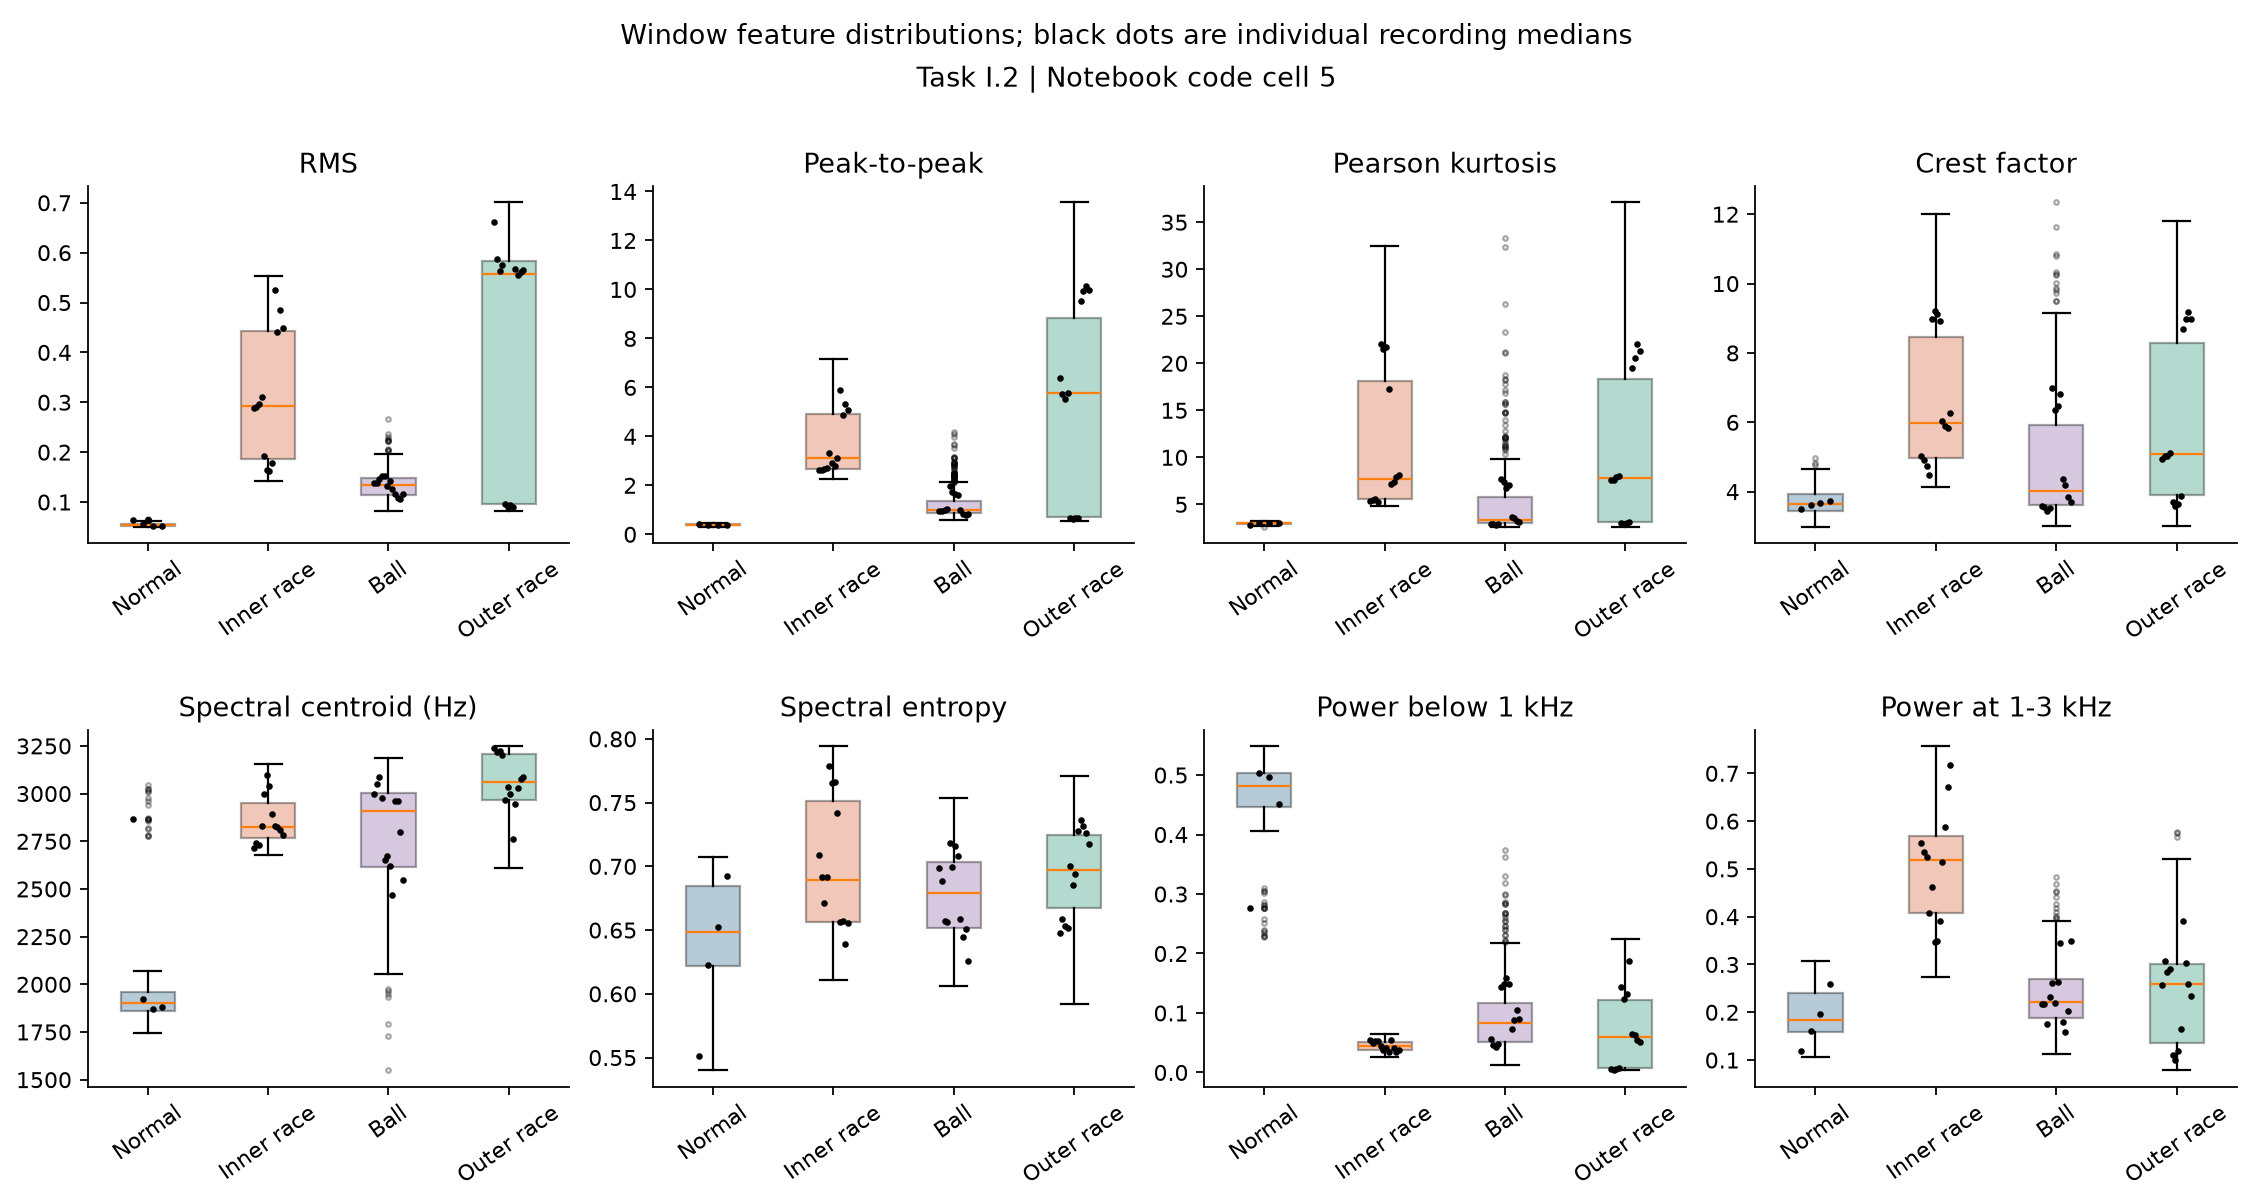

**Feature summary table.** Class minima, medians and maxima quantify the distributions above. Wide within-class ranges, particularly for fault amplitudes and kurtosis, show why typical values must be read alongside variability. The class column repeats across the three blocks.

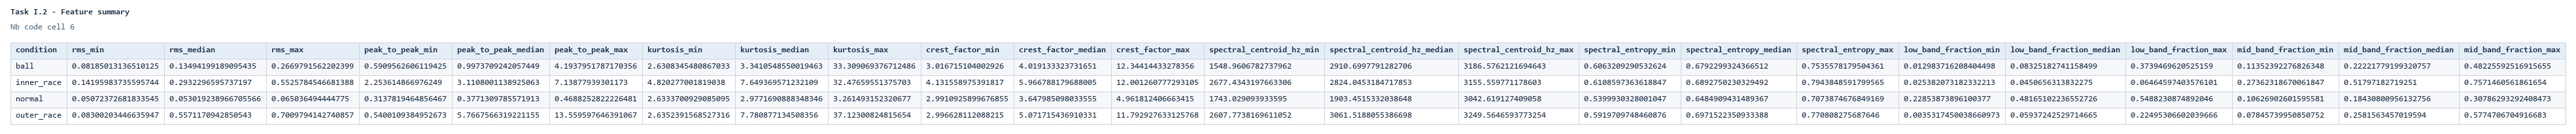

**Feature correlation table.** The numerical coefficients provide the exact Spearman relationships visualised next. Large absolute coefficients indicate overlapping information, but do not by themselves justify removing a feature.

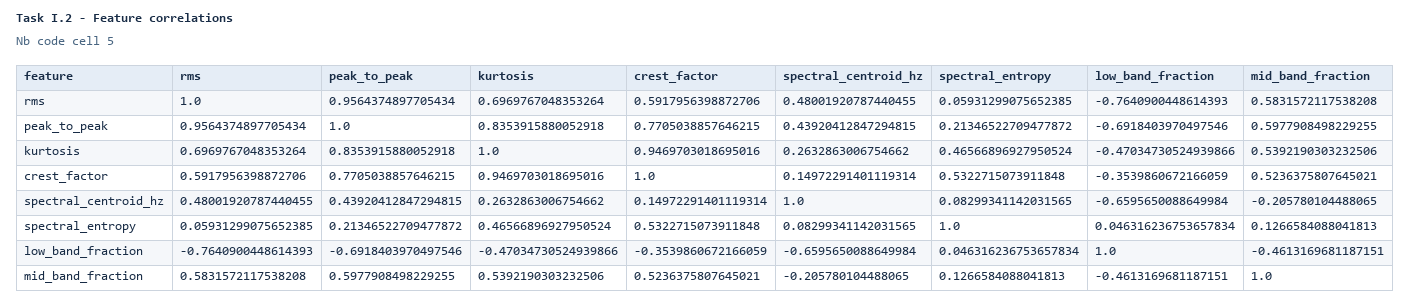

**Feature correlation figure.** RMS and peak-to-peak form a strongly related amplitude pair; kurtosis and crest factor form a strongly related impulsiveness pair. Spectral entropy has weaker relationships with most other descriptors. These are pooled dataset relationships, not causal effects.

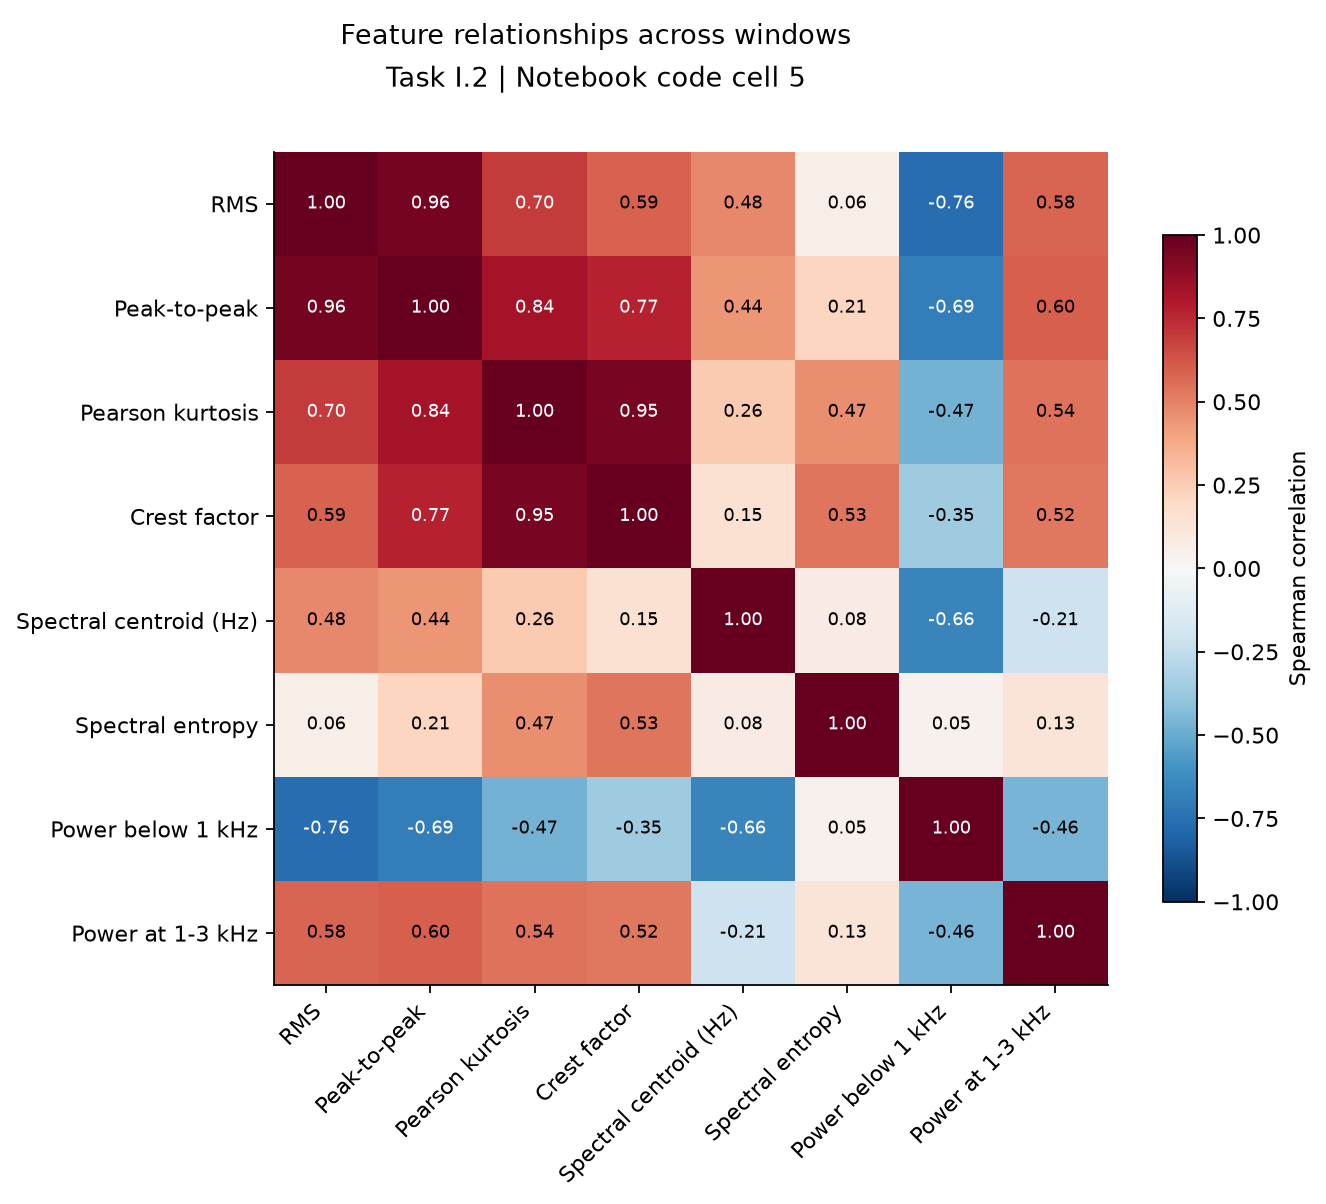

In [6]:
# Show the original samples, not the filtered signal, when examining peak truncation (clipping).
fig, axes = plt.subplots(2, 2, figsize=(11, 6), layout='constrained')
for i, file_id in enumerate([236, 237]):
    x = raw_signals[file_id]
    peak = int(np.argmax(np.abs(x)))
    left, right = max(0, peak - 24), min(len(x), peak + 25)
    axes[i, 0].plot(np.arange(left, right) / FS, x[left:right], marker='.', lw=.8)
    axes[i, 0].set(title=f'{file_id}: raw samples around largest peak',
                   xlabel='Time in original recording (s)', ylabel='Acceleration (source units)')
    axes[i, 1].hist(x, bins=100, color=COLORS[3])
    axes[i, 1].set(title=f'{file_id}: full raw amplitude distribution',
                   xlabel='Acceleration (source units)', ylabel='Sample count', yscale='log')
save_figure(fig, 'I2_anomaly_diagnostics.png')

q1, q3 = X.quantile(.25), X.quantile(.75)
iqr = q3 - q1
outside = X.lt(q1 - 3 * iqr) | X.gt(q3 + 3 * iqr)
feature_audit = pd.DataFrame({'dtype': X.dtypes.astype(str), 'missing': X.isna().sum(),
                              'non_finite': (~np.isfinite(X)).sum(), 'minimum': X.min(),
                              'median': X.median(), 'maximum': X.max(),
                              'outside_3IQR': outside.sum()})
feature_audit.to_csv(DATA / 'I2_feature_audit.csv', index_label='feature')
render_data_table('I2_feature_audit.csv', 'Task I.2 - Feature audit', 6)
summary = features.groupby('condition')[FEATURES].agg(['min', 'median', 'max'])
summary.columns = [f'{feature}_{statistic}' for feature, statistic in summary.columns]
summary.to_csv(DATA / 'I2_feature_summary.csv', index_label='condition')
render_data_table('I2_feature_summary.csv', 'Task I.2 - Feature summary', 6)


**Anomaly diagnostics.** The benchmark identifies possible peak truncation (clipping) in recordings 236 and 237; both are retained with quality flags. The left panels in the picture show raw samples around the largest absolute peak. The right panels show full amplitude distributions on a logarithmic count scale, highlighting rare extremes. These views help inspect possible peak truncation (clipping) but do not confirm it; no calibrated sensor limit is inferred.

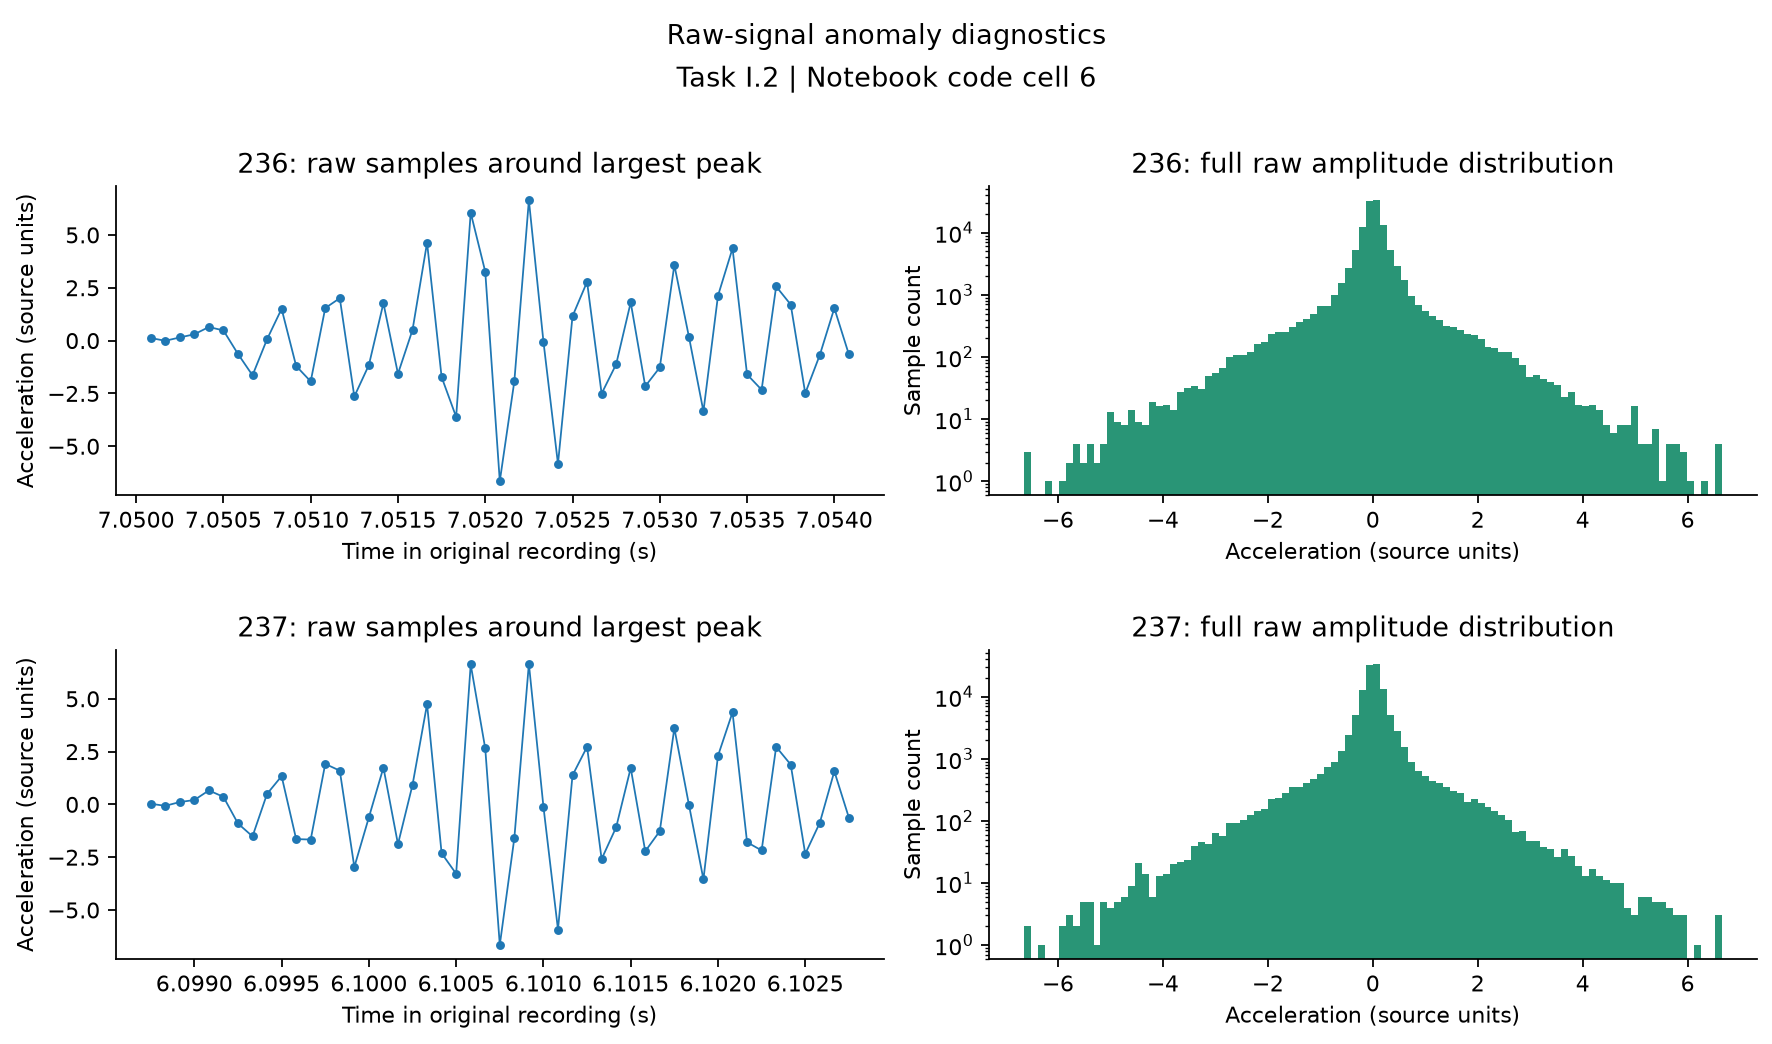

**Feature audit table.** All eight predictors are finite and complete. The three-IQR counts are descriptive flags, not deletion criteria: pooled thresholds can flag legitimate differences between classes, including minority-class behaviour.

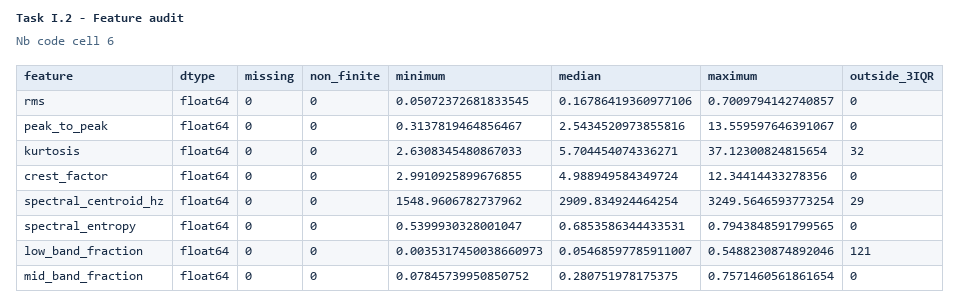

### Preprocessing decisions

The signal transformations and feature extraction above are applied uniformly and do not estimate population parameters from held-out data. Missing DE samples or zero-energy windows cause an explicit validation failure rather than silently interpolating vibration or replacing undefined features. In the audited data no predictor imputation is required. Missing RPM and not-applicable diameter remain metadata missingness.

Feature units and ranges differ, so the model pipeline uses **StandardScaler**: each feature is centred and divided by its training standard deviation. The factory below is intentionally unfitted. Task I.3 will establish training and evaluation partitions; scaling must be fitted only inside each training fold. The features CSV therefore contains unscaled predictors. No oversampling, intentional peak truncation (clipping), or automatic outlier removal is applied. The correlated descriptors remain available for a training-only comparison later; the full-data correlation plot does not select model inputs using test labels.

In [7]:
def make_preprocessor():
    """Create an unfitted scaler; fit only on training data within each evaluation fold."""
    return Pipeline([('scale', StandardScaler())])


preprocessor = make_preprocessor()
assert not hasattr(preprocessor.named_steps['scale'], 'mean_')
print('Prepared X:', X.shape, '| target:', y.shape, '| recording groups:', groups.nunique())
print('Scaling pipeline created without fitting. No classifier is trained in Task I.2.')

Prepared X: (1578, 8) | target: (1578,) | recording groups: 40
Scaling pipeline created without fitting. No classifier is trained in Task I.2.


### Observations

- **Structure and completeness:** all 40 ID-matched DE signals are float64 column vectors. Normal recordings contain 243,938-485,643 samples at 48 kHz; fault recordings contain 121,265-122,917 samples at 12 kHz. Recording 97 is shorter (5.08 s), while the others last approximately 10.1-10.2 s. There are no missing or infinite selected acceleration values, no entirely constant signals, and no exact duplicate selected DE signals.
- **Container and metadata anomalies:** `99.mat` additionally contains exact copies of the DE and FE signals from `98.mat`. Selecting `X099_DE_time` avoids counting that embedded recording twice. RPM is absent from 98 and 99; it remains missing metadata. The longest identical-sample run is three samples, which does not establish a dropout.
- **Prepared data and imbalance:** preprocessing yields **1,578 windows and eight finite numerical predictors**, with no exact duplicate windows or feature vectors. Normal operation contributes **138 windows (8.75%)**, versus **480 (30.42%)** per fault class, a largest-to-smallest ratio of **3.48**. This reflects both recording counts and recording durations. No oversampling is applied; evaluation must account for the minority class and related windows.
- **Feature relationships:** median RMS is 0.053 for normal, 0.293 for inner-race, 0.135 for ball and 0.557 for outer-race recordings, in source acceleration units. Median Pearson kurtosis is 2.98, 7.65, 3.34 and 7.78, respectively. These patterns support amplitude and impulsiveness descriptors, but the fault-class distributions overlap and their recording medians vary substantially. RMS and peak-to-peak are strongly correlated (Spearman 0.96), as are kurtosis and crest factor (0.95); correlation alone does not establish which descriptor to remove.
- **Anomalies and treatment:** the benchmark flags possible peak truncation (clipping) in 236DE and 237DE. These records are retained and flagged; isolated large peaks are not automatically invalid. Global three-IQR screens flag tails in kurtosis and frequency features, but such thresholds can flag valid class structure, including minority-class behaviour. No unsupported physical amplitude limit, outlier deletion, or predictor imputation is imposed. Feature-domain checks pass. Filtering and mean removal are applied as documented; training-only scaling is defined for fitting after the Task I.3 partition.

## Task I.3 - Classification Strategy and Baseline

We split by motor load: 0-1 HP for training (20 recordings; 778 windows), 2 HP for validation (10; 400), and 3 HP for testing (10; 400). Every partition contains all four classes and three fault diameters. Entire recordings remain together. This evaluates transfer across operating loads rather than recognising related windows from familiar recordings.

Training fits models; validation selects hyperparameters and preprocessing settings. The test partition is reserved for final evaluation after selection. Any cross-validation within training must preserve recording boundaries. Shared bearing specimens and fault configurations remain a limitation: this design does not measure transfer to unseen bearings. Task I.2 explored the full dataset, so testing is reserved from subsequent tuning but is not completely blind.

Leakage controls exclude recording identifiers, load, RPM, fault diameter, hashes and quality flags from predictors. Scaling and any learned preprocessing are fitted only on training data, within folds where applicable.

Our sole tuning and selection metric is macro-F1: the unweighted mean of class F1 scores, giving the minority normal class equal importance while considering precision and recall. The baseline predicts the most frequent training class, with alphabetical tie-breaking.

In [8]:
from itertools import combinations
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score


def define_partitions(frame):
    """Assign fixed load partitions and verify class coverage and recording isolation."""
    result = frame[['recording_id', 'condition', 'load_hp', 'window_index',
                    'window_sha256', 'specimen_group']].copy()
    result['partition'] = result['load_hp'].map({0: 'training', 1: 'training',
                                                2: 'validation', 3: 'test'})
    assert result['partition'].notna().all()
    assert result.groupby('recording_id')['partition'].nunique().eq(1).all()
    assert not result.duplicated(['recording_id', 'window_index']).any()
    parts = {name: result.loc[result['partition'].eq(name)]
             for name in ['training', 'validation', 'test']}
    for part in parts.values():
        assert set(part['condition']) == set(CLASSES)
    for first, second in combinations(parts.values(), 2):
        assert set(first['recording_id']).isdisjoint(second['recording_id'])
        assert set(first['window_sha256']).isdisjoint(second['window_sha256'])
    for name, part in parts.items():
        fault_sizes = frame.loc[part.index].groupby('condition')['diameter_inches']
        assert fault_sizes.nunique().drop('normal').eq(3).all()
    return result


def primary_score(actual, predicted):
    """Compute macro-F1 over all four classes; undefined class F1 is zero."""
    return f1_score(actual, predicted, labels=CLASSES, average='macro', zero_division=0)


def make_majority_baseline():
    """Predict the training-majority class; sorted string classes resolve ties alphabetically."""
    return DummyClassifier(strategy='most_frequent')


split_inventory = define_partitions(features)
split_inventory.to_csv(DATA / 'I3_split_inventory.csv', index=False)
render_data_table('I3_split_inventory.csv', 'Task I.3 - Partition inventory', 8)
split_masks = {name: split_inventory['partition'].eq(name)
               for name in ['training', 'validation', 'test']}
split_summary = split_inventory.groupby('partition').agg(
    recordings=('recording_id', 'nunique'), windows=('window_index', 'size'))
display(split_summary.reindex(['training', 'validation', 'test']))

# The reference classifier learns only training class counts; it ignores feature values.
baseline = make_majority_baseline()
baseline.fit(X.loc[split_masks['training']], y.loc[split_masks['training']])
validation_prediction = baseline.predict(X.loc[split_masks['validation']])
baseline_validation_f1 = primary_score(y.loc[split_masks['validation']], validation_prediction)
assert set(validation_prediction) == {'ball'}  # Three fault classes tie in the training data.
print(f'Majority baseline: {validation_prediction[0]}; validation macro-F1 = {baseline_validation_f1:.4f}')
print('All partition checks passed. No test predictions or test scores were computed.')

,recordings,windows
partition,,
training,20,778
validation,10,400
test,10,400


Majority baseline: ball; validation macro-F1 = 0.1154
All partition checks passed. No test predictions or test scores were computed.


## Task I.4 - SVM Modeling

StandardScalerâ€“SVC pipelines compare linear and RBF kernels using the eight features and fixed I.3 split (778 training; 400 validation). The scaler is fitted on training data only. We fixed `class_weight='balanced'` for both SVM kernels to address the normal-class imbalance, keeping this setting unchanged throughout hyperparameter tuning. Weights are calculated automatically from training class frequencies: approximately 3.3534 for normal and 0.8104 for each fault class, giving each class equal total weight in the training objective. PredefinedSplit searches without refitting on validation; the test remains unscored [I.4-1, I.4-2].

C spans 0.001â€“1000; RBF gamma spans 0.0001â€“100, in decade steps (56 configurations). A strictly improving boundary permits one decade extension; none was needed. Validation macro-F1 alone selects models; ties prefer smaller C, then gamma, then the linear kernel.

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, PredefinedSplit, ParameterGrid
from sklearn.metrics import make_scorer


def make_svm(kernel, C=1.0, gamma='scale'):
    """Scale training features and fit a class-balanced support vector classifier."""
    return Pipeline([('scale', StandardScaler()),
                     ('svm', SVC(kernel=kernel, C=C, gamma=gamma,
                                 class_weight='balanced', cache_size=256))])


# Match saved partition membership by recording and window, never by accidental row order.
i4_keys = ['recording_id', 'window_index']
i4_partition = split_inventory.set_index(i4_keys)['partition'].reindex(
    pd.MultiIndex.from_frame(features[i4_keys]))
assert i4_partition.notna().all()
i4_train = i4_partition.eq('training').to_numpy()
i4_val = i4_partition.eq('validation').to_numpy()
i4_dev = i4_train | i4_val
assert (i4_train.sum(), i4_val.sum()) == (778, 400)
assert not features.loc[i4_dev, 'load_hp'].eq(3).any()
i4_cv = PredefinedSplit(np.where(i4_train[i4_dev], -1, 0))


def search_svm(kernel, grid, phase):
    """Score a fixed training/validation split without refitting on validation data."""
    search = GridSearchCV(make_svm(kernel), grid, scoring=make_scorer(primary_score),
                          cv=i4_cv, refit=False, return_train_score=True,
                          error_score='raise', n_jobs=1)
    search.fit(X.loc[i4_dev], y.loc[i4_dev])
    results = search.cv_results_
    return pd.DataFrame([
        {'kernel': kernel, 'phase': phase, 'C': p['svm__C'],
         'gamma': p.get('svm__gamma', np.nan),
         'training_macro_f1': results['mean_train_score'][i],
         'validation_macro_f1': results['mean_test_score'][i]}
        for i, p in enumerate(results['params'])])


def choose_svm(results):
    """Maximise validation macro-F1; numerical ties prefer lower C, then gamma."""
    best = results['validation_macro_f1'].max()
    tied = results.loc[np.isclose(results['validation_macro_f1'], best,
                                 atol=1e-12, rtol=0)]
    return tied.sort_values(['C', 'gamma'], na_position='last').iloc[0]


def tune_svm(kernel):
    """Search logarithmic grids, allowing one extension of a strictly improving edge."""
    axes = {'svm__C': list(np.logspace(-3, 3, 7))}
    if kernel == 'rbf':
        axes['svm__gamma'] = list(np.logspace(-4, 2, 7))
    result = search_svm(kernel, axes, 'initial')
    selected = choose_svm(result)
    expanded = {key: list(values) for key, values in axes.items()}
    for parameter in ['C'] + (['gamma'] if kernel == 'rbf' else []):
        profile = result.groupby(parameter)['validation_macro_f1'].max().sort_index()
        values = profile.index.to_list()
        if selected[parameter] == values[0] and profile.iloc[0] > profile.iloc[1] + 1e-12:
            expanded['svm__' + parameter].insert(0, values[0] / 10)
        elif selected[parameter] == values[-1] and profile.iloc[-1] > profile.iloc[-2] + 1e-12:
            expanded['svm__' + parameter].append(values[-1] * 10)
    seen = {tuple(sorted(p.items())) for p in ParameterGrid(axes)}
    extra = [{key: [value] for key, value in p.items()}
             for p in ParameterGrid(expanded) if tuple(sorted(p.items())) not in seen]
    if extra:
        result = pd.concat([result, search_svm(kernel, extra, 'extension')], ignore_index=True)
    return result


i4_results = pd.concat([tune_svm('linear'), tune_svm('rbf')], ignore_index=True)
assert i4_results['phase'].eq('initial').sum() == 56
i4_results['train_validation_gap'] = (i4_results['training_macro_f1'] -
                                       i4_results['validation_macro_f1'])
i4_results['selected'] = False
i4_models, i4_rows = {}, []
for kernel in ['linear', 'rbf']:
    selected = choose_svm(i4_results.loc[i4_results['kernel'].eq(kernel)])
    model = make_svm(kernel, float(selected['C']),
                     float(selected['gamma']) if kernel == 'rbf' else 'scale')
    model.fit(X.loc[i4_train], y.loc[i4_train])
    assert model['svm'].fit_status_ == 0
    np.testing.assert_allclose(model['scale'].mean_, X.loc[i4_train].mean())
    np.testing.assert_allclose(model['scale'].var_, X.loc[i4_train].var(ddof=0))
    training_score = primary_score(y.loc[i4_train], model.predict(X.loc[i4_train]))
    validation_score = primary_score(y.loc[i4_val], model.predict(X.loc[i4_val]))
    np.testing.assert_allclose([training_score, validation_score],
                              [selected['training_macro_f1'], selected['validation_macro_f1']])
    i4_results.loc[selected.name, 'selected'] = True
    i4_models[kernel] = model
    i4_rows.append({'model': kernel, 'C': selected['C'], 'gamma': selected['gamma'],
                    'training_macro_f1': training_score, 'validation_macro_f1': validation_score,
                    'train_validation_gap': training_score - validation_score,
                    'support_vectors': int(model['svm'].n_support_.sum())})
i4_rows.append({'model': 'majority', 'C': np.nan, 'gamma': np.nan,
                'training_macro_f1': primary_score(y.loc[i4_train], baseline.predict(X.loc[i4_train])),
                'validation_macro_f1': primary_score(y.loc[i4_val], baseline.predict(X.loc[i4_val])),
                'train_validation_gap': np.nan, 'support_vectors': np.nan})
i4_comparison = pd.DataFrame(i4_rows)
i4_results.to_csv(DATA / 'I4_tuning_results.csv', index=False)
i4_comparison.to_csv(DATA / 'I4_model_comparison.csv', index=False)


In [10]:
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont


def render_i4_table(csv_name, title):
    """Render a complete CSV as a readable, content-fitted PNG table."""
    frame = pd.read_csv(DATA / csv_name)
    font = ImageFont.truetype('C:/Windows/Fonts/consola.ttf', 15)
    bold = ImageFont.truetype('C:/Windows/Fonts/consolab.ttf', 15)
    headings = [column.replace('_', ' ') for column in frame.columns]
    rows = []
    for values in frame.itertuples(index=False, name=None):
        row = []
        for column, value in zip(frame.columns, values):
            if pd.isna(value):
                row.append('-')
            elif isinstance(value, (float, np.floating)):
                row.append(f'{value:.4f}' if 'f1' in column or 'gap' in column else f'{value:g}')
            else:
                row.append(str(value))
        rows.append(row)
    widths = [int(max(bold.getlength(headings[j]),
                      max(font.getlength(row[j]) for row in rows))) + 16
              for j in range(len(headings))]
    image = Image.new('RGB', (sum(widths) + 32, 85 + 29 * len(rows)), 'white')
    draw = ImageDraw.Draw(image)
    draw.text((16, 12), title, fill='#172b45', font=bold)
    code_cell = 10 if csv_name.startswith('I4_') else 12
    reference_font = ImageFont.truetype('C:/Windows/Fonts/consola.ttf', 13)
    draw.text((16, 30), f'Nb code cell {code_cell}', fill='#486581', font=reference_font)
    for i, row in enumerate([headings] + rows):
        left, top = 16, 48 + i * 29
        for width, value in zip(widths, row):
            draw.rectangle((left, top, left + width, top + 29),
                           fill='#e5edf6' if i == 0 else ('#f5f7fa' if i % 2 else 'white'),
                           outline='#ccd4de')
            draw.text((left + 8, top + 6), value, fill='#172b45', font=bold if i == 0 else font)
            left += width
    output = TABLE_FIGURES / Path(csv_name).with_suffix('.png').name
    image.save(output)


render_i4_table('I4_model_comparison.csv', 'Task I.4 - Model comparison (macro-F1)')
render_i4_table('I4_tuning_results.csv', 'Task I.4 - Hyperparameter search (macro-F1)')
rbf_results = i4_results.loc[i4_results['kernel'].eq('rbf')]
selected_rbf = choose_svm(rbf_results)
heatmap = rbf_results.pivot(index='C', columns='gamma', values='validation_macro_f1').sort_index().sort_index(axis=1)
fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)
image = ax.imshow(heatmap, vmin=0, vmax=1, cmap='viridis', aspect='auto')
ax.set_xticks(range(len(heatmap.columns)), [f'{v:g}' for v in heatmap.columns])
ax.set_yticks(range(len(heatmap.index)), [f'{v:g}' for v in heatmap.index])
for row in range(len(heatmap.index)):
    for col in range(len(heatmap.columns)):
        value = heatmap.iloc[row, col]
        ax.text(col, row, f'{value:.3f}', ha='center', va='center',
                color='white' if value < .55 else 'black', fontsize=9)
from matplotlib.patches import Rectangle
selected_row = heatmap.index.get_loc(selected_rbf['C'])
selected_col = heatmap.columns.get_loc(selected_rbf['gamma'])
ax.add_patch(Rectangle((selected_col-.5, selected_row-.5), 1, 1,
                        fill=False, edgecolor='#ff7600', linewidth=3))
ax.set(xlabel='RBF gamma', ylabel='C', title='Validation macro-F1: RBF SVM (orange border: selected)')
fig.colorbar(image, ax=ax, label='Macro-F1')
save_figure(fig, 'I4_rbf_validation_heatmap.png', dpi=180)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True, constrained_layout=True)
for ax, kernel in zip(axes, ['linear', 'rbf']):
    subset = i4_results.loc[i4_results['kernel'].eq(kernel)]
    selected = choose_svm(subset)
    if kernel == 'rbf':
        subset = subset.loc[subset['gamma'].eq(selected['gamma'])]
    subset = subset.sort_values('C')
    ax.semilogx(subset['C'], subset['training_macro_f1'], 'o-', label='Training')
    ax.semilogx(subset['C'], subset['validation_macro_f1'], 's-', label='Validation')
    ax.axvline(selected['C'], color='grey', linestyle=':', label='Selected C')
    ax.axhline(i4_comparison.iloc[-1]['validation_macro_f1'], color='purple',
               linestyle='--', label='Majority validation')
    ax.set(xlabel='C', ylim=(0, 1.03), title=kernel.capitalize() +
           (f" (gamma={selected['gamma']:g})" if kernel == 'rbf' else ''))
    ax.grid(alpha=.2)
axes[0].set_ylabel('Macro-F1')
axes[1].legend(fontsize=8)
save_figure(fig, 'I4_regularisation_curves.png', dpi=180)


**Model comparison.** Both selected kernels achieve validation macro-F1 1.0000, versus 0.1154 for the majority baseline. Linear uses 63 support vectors; RBF uses 139. The gap is training minus validation.

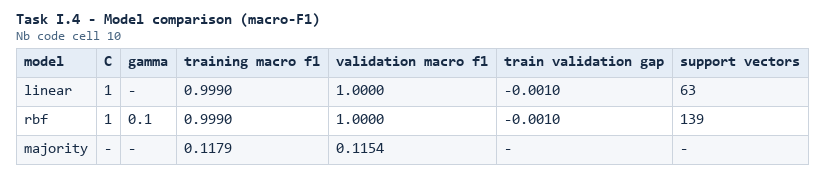

**Hyperparameter effects.** The heatmap shows every RBF validation score; the orange border marks the selected pair. C controls the penalty for margin violations; gamma controls locality [I.4-1, I.4-3]. At gamma = 100, even the best validation macro-F1 is only 0.3023.

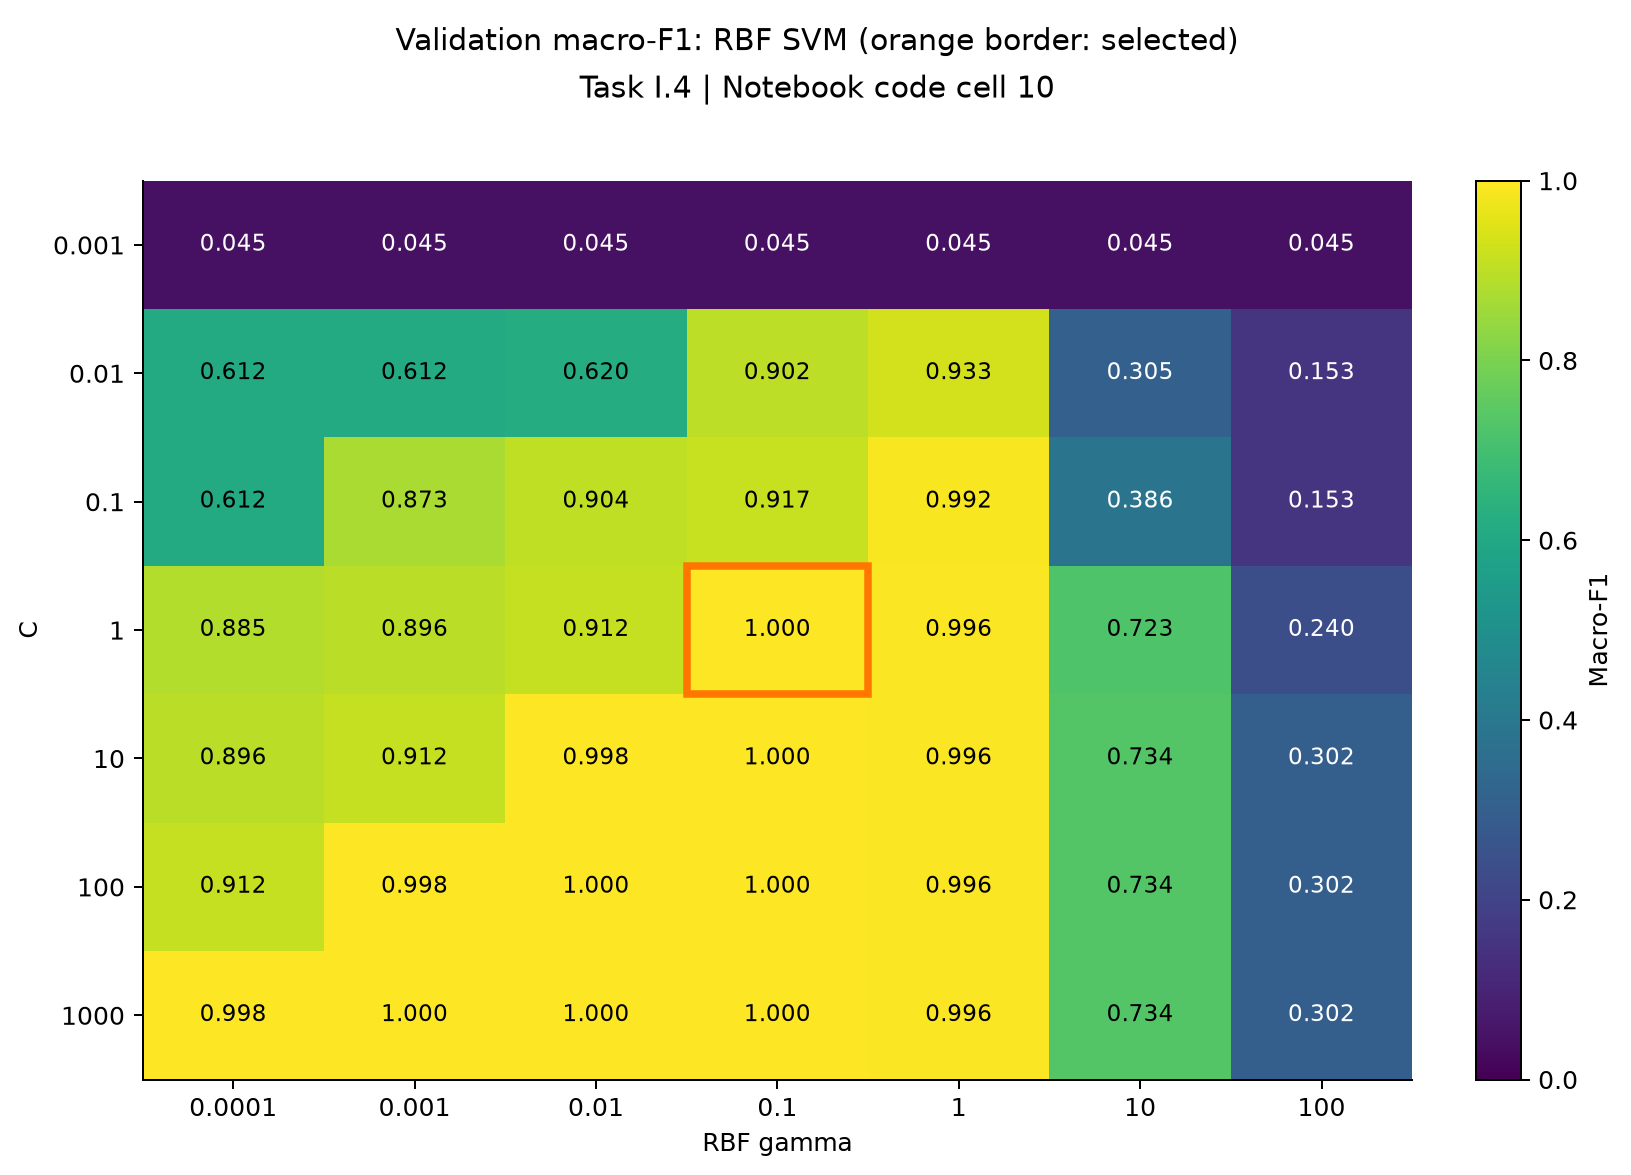

**Fit and kernel choice.** Curves vary C, holding RBF gamma at 0.1. Small C reduces both scores, indicating underfitting. For linear C â‰¥ 100, training reaches 1.0000 while validation falls to 0.9938: mild overfitting evidence, although load shift also affects gaps. Selected models show no positive gap.

Linear SVM is retained (C = 1); RBF (C = 1, gamma = 0.1) adds no validation benefit. Engineered amplitude and spectral features already support linear separation. Perfect validation remains conditional on shared specimens, earlier full-dataset exploration and repeated validation selection.

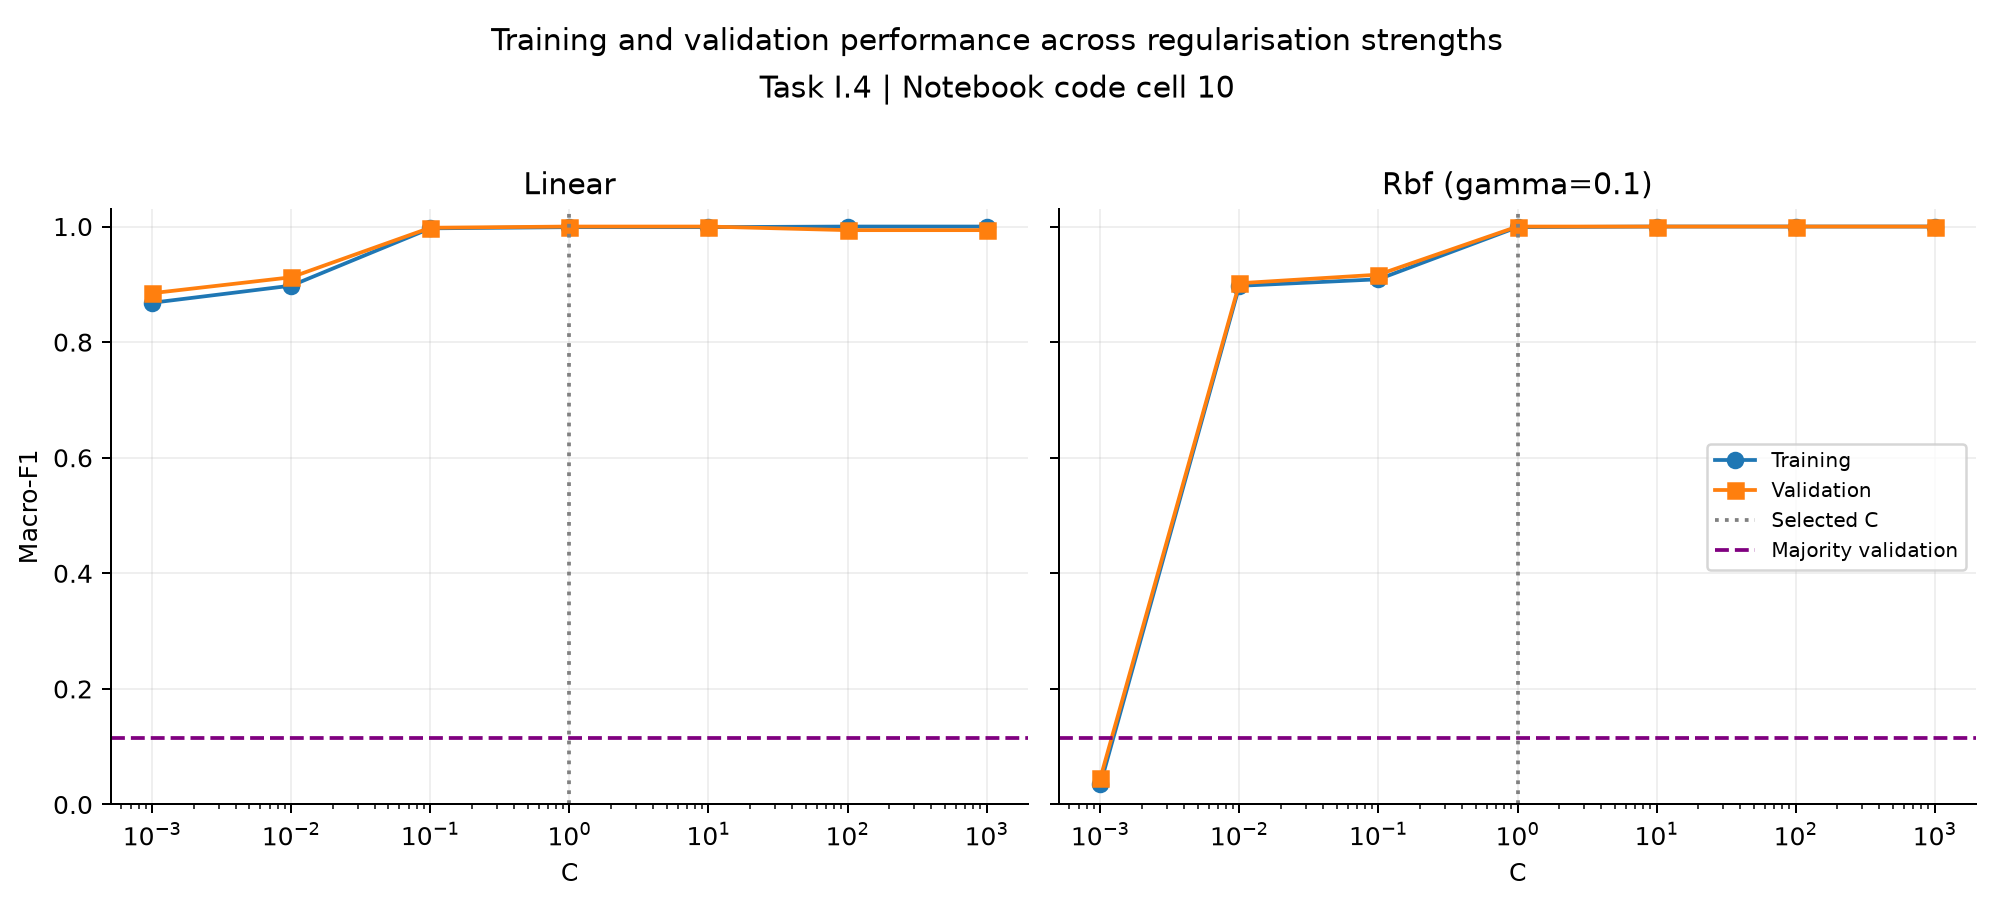

## Task I.5 - Model Evaluation and Comparison

Both I.4 SVMs are compared with balanced multinomial logistic regression using L2 regularisation. Logistic C was selected from 0.001â€“1000 in decade steps using the unchanged training/validation split and macro-F1; ties favour smaller C. C = 1 gave validation macro-F1 0.9979. Settings were frozen before test scoring.

All models use identical eight-feature inputs, training-fitted StandardScaler preprocessing and the same 400 test windows (3 HP). Models remain fitted on the original 778 training windows.

In [11]:
import warnings
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix


def make_logistic(C=1.0):
    """Fit scaled, balanced multinomial logistic regression with L2 regularisation."""
    return Pipeline([('scale', StandardScaler()),
                     ('classifier', LogisticRegression(C=C, l1_ratio=0,
                         solver='lbfgs', class_weight='balanced', max_iter=5000, tol=1e-6))])


# Use the same predefined split and macro-F1 selection rule as I.4, before accessing test results.
with warnings.catch_warnings():
    warnings.simplefilter('error', ConvergenceWarning)
    i5_search = GridSearchCV(make_logistic(), {'classifier__C': np.logspace(-3, 3, 7)},
        scoring=make_scorer(primary_score), cv=i4_cv, refit=False,
        return_train_score=True, error_score='raise', n_jobs=1)
    i5_search.fit(X.loc[i4_dev], y.loc[i4_dev])
i5_tuning = pd.DataFrame({
    'C': [p['classifier__C'] for p in i5_search.cv_results_['params']],
    'training_macro_f1': i5_search.cv_results_['mean_train_score'],
    'validation_macro_f1': i5_search.cv_results_['mean_test_score']})
i5_best = i5_tuning['validation_macro_f1'].max()
i5_selected = i5_tuning.loc[np.isclose(i5_tuning['validation_macro_f1'],
                           i5_best, atol=1e-12, rtol=0)].sort_values('C').iloc[0]
i5_tuning['selected'] = i5_tuning['C'].eq(i5_selected['C'])
i5_tuning.to_csv(DATA / 'I5_logistic_tuning.csv', index=False)

# Freeze all three classifiers before obtaining any test predictions. Keep original training only.
i5_models = {'linear_svm': clone(i4_models['linear']),
             'rbf_svm': clone(i4_models['rbf']),
             'logistic_regression': make_logistic(float(i5_selected['C']))}
with warnings.catch_warnings():
    warnings.simplefilter('error', ConvergenceWarning)
    for model in i5_models.values():
        model.fit(X.loc[i4_train], y.loc[i4_train])
        np.testing.assert_allclose(model['scale'].mean_, X.loc[i4_train].mean())
        np.testing.assert_allclose(model['scale'].var_, X.loc[i4_train].var(ddof=0))
np.testing.assert_allclose(primary_score(y.loc[i4_val],
    i5_models['logistic_regression'].predict(X.loc[i4_val])), i5_best)
i5_test = i4_partition.eq('test').to_numpy()
assert i5_test.sum() == 400 and features.loc[i5_test, 'load_hp'].eq(3).all()
assert not (i5_test & i4_dev).any()
i5_truth = y.loc[i5_test]
i5_predictions = features.loc[i5_test, ['recording_id','window_index','condition']].copy()
i5_overall, i5_class_rows, i5_confusion_rows = [], [], []
i5_matrices = {}
for name, model in i5_models.items():
    predicted = model.predict(X.loc[i5_test])
    i5_predictions[name] = predicted
    precision, recall, f1, _ = precision_recall_fscore_support(
        i5_truth, predicted, labels=CLASSES, average='macro', zero_division=0)
    i5_overall.append({'model': name, 'accuracy': accuracy_score(i5_truth, predicted),
        'macro_precision': precision, 'macro_recall': recall, 'macro_f1': f1})
    per_class = precision_recall_fscore_support(i5_truth, predicted,
                                               labels=CLASSES, zero_division=0)
    for index, label in enumerate(CLASSES):
        i5_class_rows.append({'model': name, 'class': label,
            'precision': per_class[0][index], 'recall': per_class[1][index],
            'f1': per_class[2][index], 'support': int(per_class[3][index])})
    matrix = confusion_matrix(i5_truth, predicted, labels=CLASSES)
    assert matrix.sum() == 400
    i5_matrices[name] = matrix
    for row, actual in enumerate(CLASSES):
        for col, predicted_class in enumerate(CLASSES):
            i5_confusion_rows.append({'model': name, 'actual_class': actual,
                'predicted_class': predicted_class, 'count': int(matrix[row,col]),
                'row_percentage': 100 * matrix[row,col] / matrix[row].sum()})
i5_metrics = pd.DataFrame(i5_overall)
i5_per_class = pd.DataFrame(i5_class_rows)
i5_confusion = pd.DataFrame(i5_confusion_rows)
i5_metrics.to_csv(DATA / 'I5_model_comparison.csv', index=False)
i5_per_class.to_csv(DATA / 'I5_class_metrics.csv', index=False)
i5_confusion.to_csv(DATA / 'I5_confusion_counts.csv', index=False)
i5_predictions.to_csv(DATA / 'I5_test_predictions.csv', index=False)


In [12]:
# Reuse the I.4 renderer: complete CSV tables with fitted column widths and no row splitting.
for filename, title in [
    ('I5_logistic_tuning.csv', 'Task I.5 - Logistic regression validation search'),
    ('I5_model_comparison.csv', 'Task I.5 - Test model comparison'),
    ('I5_class_metrics.csv', 'Task I.5 - Test class-specific metrics'),
    ('I5_confusion_counts.csv', 'Task I.5 - Confusion counts and row percentages'),
    ('I5_test_predictions.csv', 'Task I.5 - Test prediction inventory')]:
    render_i4_table(filename, title)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), constrained_layout=True)
labels = ['Normal', 'Inner race', 'Ball', 'Outer race']
for ax, (name, matrix) in zip(axes, i5_matrices.items()):
    percentages = 100 * matrix / matrix.sum(axis=1, keepdims=True)
    image = ax.imshow(percentages, vmin=0, vmax=100, cmap='Blues')
    for row in range(4):
        for col in range(4):
            ax.text(col, row, f'{matrix[row,col]}\n({percentages[row,col]:.1f}%)',
                ha='center', va='center', fontsize=8,
                color='white' if percentages[row,col] > 55 else 'black')
    ax.set_xticks(range(4), labels, rotation=35, ha='right')
    ax.set_yticks(range(4), labels)
    ax.set(xlabel='Predicted class', ylabel='Actual class',
           title={'linear_svm':'Linear SVM','rbf_svm':'RBF SVM',
                  'logistic_regression':'Logistic regression'}[name])
fig.colorbar(image, ax=axes, label='Percentage within actual class', shrink=.8)
save_figure(fig, 'I5_confusion_matrices.png', dpi=180)


**Overall comparison.** Accuracy measures the proportion correct. Precision, recall and F1 are unweighted macro averages across four classes; undefined values are zero. Logistic regression has the highest observed test macro-F1 (0.9958), followed by RBF (0.9854) and linear SVM (0.7572). The validation-selected SVM remains linear; the test ranking does not trigger retuning.

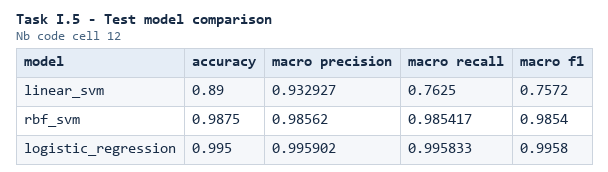

**Class-specific results.** Support is the number of actual test observations: 40 normal and 120 per fault class. Linear SVM's normal recall is only 0.1250, despite precision 1.0000: it rarely recognises normal windows, but its five normal predictions are correct.

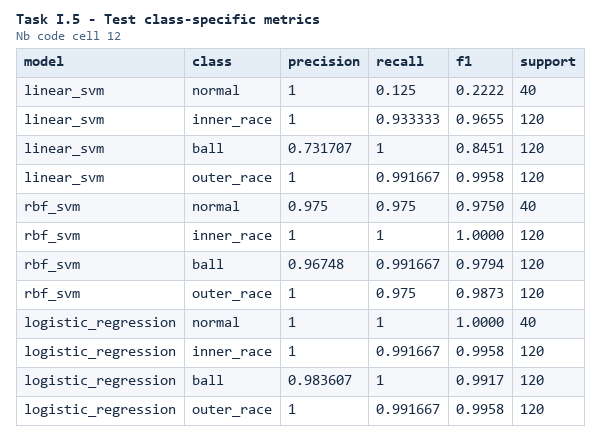

**Errors and limitations.** Matrices show counts and percentages within each actual class, using identical scales. Ball is a common erroneous destination: linear SVM sends 35 normal, eight inner-race and one outer-race window there. Logistic regression makes two errors; RBF makes five.

Perfect SVM validation did not ensure transfer to 3 HP. Logistic regression leads here, but its three-error advantage over RBF is inconclusive. Shared bearing specimens, only ten test recordings, dependent windows, one test load and earlier full-dataset exploration restrict generalisation.

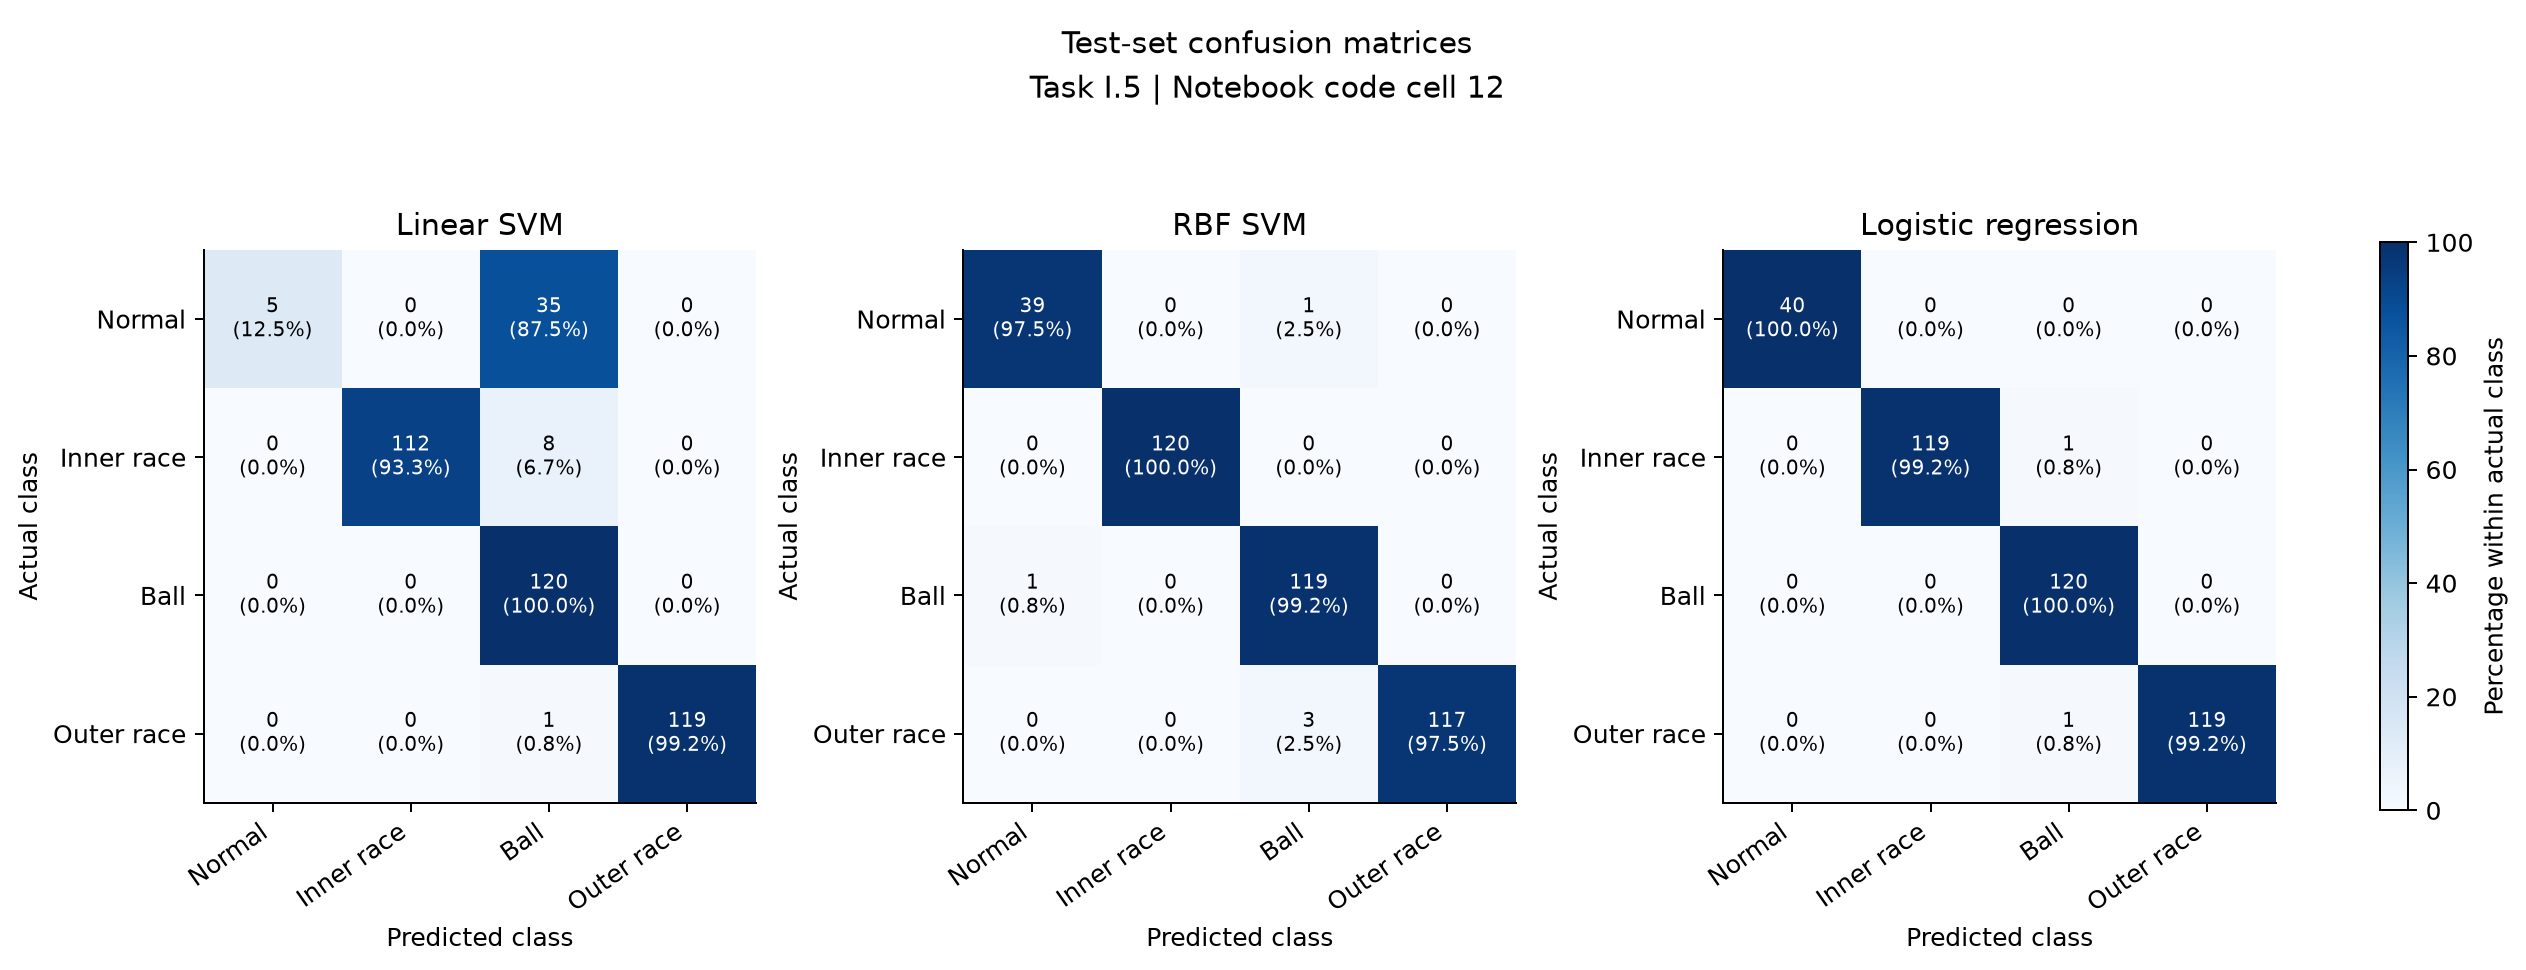